# Reading an LLM's planned algorithm in words: demo of the pipeline's CPU stages

**Artifact** `art_dbUtqBjT0tPf` (iteration 6, experiment 32) · **Model** `Qwen/Qwen2.5-7B-Instruct` (bf16) · **Instrument** the released natural-language autoencoder (NLA) pair `kitft/nla-qwen2.5-7b-L20-av` / `-ar`, which reads layer 20.

### The question
Ask an LLM to "find a path in a grid" and it writes BFS. Ask for a weighted shortest path and it writes Dijkstra. Is that choice already made, and readable, in the model's residual stream before the first code token is written? And can an edit of that state in words steer it?

The NLA has two halves:
- the **activation verbaliser (AV)** turns one layer-20 state into a short text explanation;
- the **activation reconstructor (AR)** turns a text back into a state. An explanation can therefore be edited ("… will implement Y") and patched back into the model.

Two blind LLM judges from different model families map every explanation to an algorithm of the task's catalogue, and a third resolves their disagreements. None of them sees which prompt condition produced the state.

### What the full pipeline did (`method.py`, stages S0–S9)
1. **Behaviour (S1–S3).** 8 algorithm-choice tasks. Each task has four kinds of prompt:
   - a neutral *twin* prompt (N = 50);
   - a *ban*, "do not use ⟨the default⟩" (N = 50, paired with the twin through common random numbers);
   - an *"Implement Y"* forced prompt per catalogue algorithm (N = 20);
   - for T2 only, a semantic *seed* paragraph (N = 50).

   Hidden tests plus frozen runtime-trace and AST labellers label every program.
2. **NLA readout (S4–S7, S9).** Layer-20 states are read at the end of the prompt (SPEC-3 … READ) and at generated tokens: 6,180 AV explanations, all scored by the blind judges. The baselines are:
   - the same judges reading only the visible text (text-only **NAME**);
   - an outside reader forecasting the algorithm (**PREDICT**);
   - swapped twin explanations and random perturbations;
   - a forced-prompt positive control.
3. **Causal edit (S6, S8).** The difference of two AR reconstructions (the edited minus the unedited explanation) is patched into the layer-20 states.

The run took about 2 GPU-hours on one NVIDIA L4 and about USD 2 of OpenRouter judge calls. Every stage was pre-registered in a sha256 chain: commits #0–#3, each made before its samples.

### What this notebook runs
The GPU stages need Qwen2.5-7B and the two NLA checkpoints, about 41 GB of weights, and the judges need OpenRouter; neither fits a 10-minute Colab session. Their outputs ship in `mini_demo_data.json`: states, explanations, judge verdicts and program labels. The notebook replays, with the original code, every CPU stage that reads them:

| stage | original code | replayed on the demo data |
|---|---|---|
| S3c behaviour report | `src/behaviour.py report` | defaults, ban substitutes Y\*, ban avoidance, forced adherence, paired twin→ban flips |
| S7 judges (answers stored) | `src/judges.py` | the judges' exact rubric, and every stored verdict re-resolved from the raw J1/J2/J3 answers |
| S9 readout analysis | `analysis/readout.py`, `analysis/stats.py` | the committed tests N1–N8b (exact McNemar, task-cluster bootstrap, Holm) |
| exploratory geometry | `analysis/geometry.py` | the ban displacement against the forced-algorithm directions, and classical MDS of the centroids |
| S9 figures | `src/figures.py` | F0–F3 and F6–F8, including the plots in activation space |
| S9 audit | `audit/rederive.py` | an independent re-derivation (standard library only) with a placebo |

The pipeline driver, `method.py`, is kept. It walks through every stage, runs the replayed ones, and logs what each of the other stages would need.

### The demo data
The demo data has 100 layer-20 states at **READ**, the last prompt token (the `\n` after `assistant`). Each example carries the state vector itself:
- **T1 grid path** and **T2 weighted shortest path**, the two path-search tasks: every READ state of the artifact (twin, ban, every forced algorithm, random perturbations, and T2's seed);
- **T05 two-sum**: the twin and ban states. T05 is the only task where the ban produced a substitute algorithm, so it is the only task in the primary test N1.

Each state also comes with its NLA explanations, the judges' verdicts, and the labels of the programs the model wrote from the same prompt (570 programs in all).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (the pipeline's logger) — NOT pre-installed on Colab, always install (the artifact pins 0.7.3)
_pip('loguru==0.7.3')

# numpy, scipy (analysis/stats.py), matplotlib (src/figures.py), pandas (results tables) — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# --- method.py (original import block) ---
import argparse
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/cfg.py, src/behaviour.py, src/judges.py, src/figures.py, analysis/stats.py, analysis/readout.py,
#     analysis/geometry.py, audit/rederive.py (their import blocks, merged; every module is a cell below) ---
import hashlib
import json
import math
import os
import random
import re
import resource
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any, Callable, Iterable, Sequence

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats as ss

# --- notebook only: decoding the states, the `PR` namespace, results tables and figures ---
import base64
import types

import pandas as pd
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-6/experiment-32/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EX = data["datasets"][0]["examples"]  # one example per layer-20 READ state
print(data["metadata"]["description"])
print(f"{data['datasets'][0]['dataset']}: {len(EX)} states, {sum(e['metadata_in_readout_set'] for e in EX)} of them "
      f"explained by the AV and judged; {data['metadata']['selection']['n_programs']} labelled programs attached")
print(dict(Counter(f"{e['metadata_task']}|{e['metadata_condition']}" for e in EX)))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Demo subset of art_dbUtqBjT0tPf ('Reading an LLM's planned algorithm in words'): 100 layer-20 READ states of Qwen/Qwen2.5-7B-Instruct with their NLA explanations, blind-judge verdicts, the realised programs' labels and the state vectors themselves (see build_mini_demo_data.py).
nla_readout_states: 100 states, 65 of them explained by the AV and judged; 570 labelled programs attached
{'T1|twin': 5, 'T1|ban': 5, 'T1|forced': 30, 'T2|twin': 5, 'T2|ban': 5, 'T2|forced': 25, 'T2|seed': 5, 'T05|twin': 5, 'T05|ban': 5, 'T1|rand': 5, 'T2|rand': 5}


## Configuration

The replayed stages have three tunable parameters, all Monte Carlo sizes. They change bootstrap intervals, one permutation p-value and the rarefied Hill-1 diversity. No count, rate, point estimate or exact McNemar test depends on them.
- `N_BOOT`: task-cluster bootstrap draws behind every readout interval (`analysis/stats.py`).
- `N_PERM`: sign-flip draws of the N1-swap permutation null (`analysis/readout.py`).
- `N_HILL_DRAWS`: subsamples per rarefied Hill-1 diversity in the behaviour report (`src/behaviour.py`).

They are set to the artifact's original values, 2000 / 10000 / 1000. With them the whole notebook still runs in about a minute, mostly the install cell; `1 / 1 / 1` is the smallest setting that still produces every output. The behaviour report matches the full run exactly only at `N_HILL_DRAWS = 1000`, because the Hill-1 values are Monte Carlo averages.

The other names describe what the demo data covers. Only READ states ship, so the geometry runs at READ only; the artifact also ran SPEC-1. `ROOT` stands in for the artifact folder: the notebook rebuilds the stages' input files there, and the stages write their `results/`, `figures/` and `logs/` there.

In [5]:
# ---- tunable parameters: the Monte Carlo sizes of the replayed stages (original values)
N_BOOT = 2000         # task-cluster bootstrap draws, analysis/stats.py cluster_bootstrap    (original 2000)
N_PERM = 10000        # sign-flip permutation draws of the N1-swap null, analysis/readout.py  (original 10000)
N_HILL_DRAWS = 1000   # subsamples per rarefied Hill-1 diversity, src/behaviour.py            (original 1000)

# ---- what the demo data covers (fixed by mini_demo_data.json)
DEMO_TASKS = ("T1", "T2", "T05")   # tasks with states in the data
GEOMETRY_TASKS = ("T1", "T2")      # tasks whose forced-prompt states ship (analysis/geometry.py needs the forced centroids)
GEOMETRY_POSITIONS = ("READ",)     # analysis/geometry.py positions (original ("READ", "SPEC-1"); only READ states ship)
ROOT = Path("nla_demo").resolve()  # stands in for the artifact folder: the replayed stages read and write here

## 1. Shared constants and helpers (`src/cfg.py`)

Every stage imports `src/cfg.py`. It holds the models and their revisions, the 8 tasks, the five ban templates W1–W5 with their neutral twins, the read positions, the design thresholds, and the I/O helpers.

Conventions used throughout:
- **Block l** is decoder block l (0-based), and its output is HF `hidden_states[l + 1]`. The NLA was trained on the output of block 20, i.e. `hidden_states[21]`. Stage S6 compared both conventions and chose `hs21`: reference FVE 0.695, against 0.580 for `hs20`.
- **Positions** count from the end of the prompt. READ is P−1, the `\n` after `assistant`. SPEC-1 … SPEC-3 are the last three tokens of the user content.
- A **CRN slot** (task, template, k) fixes the uniform random numbers of the sampler, and every arm shares them. Twin and ban programs from the same slot are therefore paired.

The file is copied unchanged except for three changes, each marked `# notebook:`:
- `ROOT` comes from the config cell;
- `N_BOOT` comes from the config cell;
- `TASKS` is narrowed to the demo tasks.

In [6]:
"""Shared constants, paths and utilities for the iteration-6 artifact 'Reading the planned algorithm in words'.

Conventions (stated again in README.md):
- BLOCK l = decoder block l (0-based); its output is HF hidden_states[l + 1]. The NLA checkpoint was trained on the
  output of block 20 (= hidden_states[21]); the README snippet reads hidden_states[20]. Both are cached and the
  pre-registered convention check in S6 picks one (cfg.LAYER_CONVENTIONS).
- Positions are counted from the END of the prompt: READ = P-1 (the '\\n' after 'assistant'); SPEC-1..SPEC-3 = the
  three user-content tokens just before the user turn's '<|im_end|>' (P-6, P-7, P-8 under the Qwen2.5 tail).
- CRN slot = (task, template w, k); uniforms u_stream(task, w, k) (PCG64 of a sha256 seed) are shared by EVERY arm.
"""

# src/cfg.py (its imports are in the imports cell)

# ROOT = Path(__file__).resolve().parents[1]   # notebook: ROOT is set in the config cell
INPUTS = ROOT / "inputs"
E8 = INPUTS / "exp8"
E11 = INPUTS / "exp11"
E7 = INPUTS / "exp7"
E27 = INPUTS / "exp27"
E28 = INPUTS / "exp28"
E6 = INPUTS / "exp6"
E18 = INPUTS / "exp18"
BENCH = E11 / "bench"
SUITE = E8 / "suite"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
AUDIT_DIR = ROOT / "audit"
CACHE_DIR = ROOT / "cache"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, AUDIT_DIR, CACHE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# the declared dataset dependency art_j3Rm_lr2nzR6 (read-only). The published repository holds it as a sibling folder
# of this artifact; the environment variable ART_J3RM_DIR points elsewhere (e.g. the run volume where it was produced).
DEP_DATASET_DIR = Path(os.environ.get("ART_J3RM_DIR", str(ROOT.parent / "art_j3Rm_lr2nzR6")))

# ------------------------------------------------------------------------------------------------ models
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
MODEL_REVISION = "a09a35458c702b33eeacc393d103063234e8bc28"
AV_ID = "kitft/nla-qwen2.5-7b-L20-av"
AV_REVISION = "b88469162777ae6553bc14208eb0cb579336f8f4"
AR_ID = "kitft/nla-qwen2.5-7b-L20-ar"
AR_REVISION = "e2c9e57eac213d37a31612087f645ab6332c1bb6"
N_LAYERS = 28
D_MODEL = 3584
IM_END = 151645
ENDOFTEXT = 151643
EOS_IDS = (IM_END, ENDOFTEXT)
MAX_NEW_TOKENS = 1024
MAX_NEW_PATH = 1536
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n"
ENGINE_TAG = "bf16-hf"
PRECISION = "bf16"
LAYER_CONVENTIONS = {"hs20": 20, "hs21": 21}  # hidden_states index -> hooked block = index - 1
EXTRACTION_LAYER = 20

# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH_TASKS = ("T03", "T05", "T06", "T10", "T04", "R6")
TASKS = ("T1", "T2", "T03", "T05", "T06", "T10", "T04", "R6")
TASKS = tuple(t for t in TASKS if t in DEMO_TASKS)  # notebook: only these tasks' states and programs are in the data
EXP8_TASK = {"T1": "t1", "T2": "t2"}
# the earlier family's (Qwen3-8B) defaults; used only to pick the twin's neutral noun before this model's default
# is known (protocol: the twin is token-length matched to the ban of the prior default)
PRIOR_DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set",
                 "T05": "hash_map", "T10": "union_find", "R6": "binary_search"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
N_FORCED_PARAPHRASES = 5

# ------------------------------------------------------------------------------------------------ design
TWIN_SLOTS = list(range(10))          # k 0-9 per template -> N = 50
EXTRA_TWIN_SLOTS = list(range(10, 20))  # NO-DEFAULT tasks: the ban's 50 samples go to twin slots 10-19
FORCED_SLOTS = list(range(4))         # 5 paraphrases x 4 slots = 20 per catalogue Y
CAUSAL_SLOTS = list(range(6))         # W1-W5 x slots 0-5 = 30 per cell
GEN_POSITIONS = (1, 2, 4, 8, 16)      # generated-token read positions g1..g16 (1-based generated index)
PREFILL_POS = ("SPEC-3", "SPEC-2", "SPEC-1", "READ")
POS_OFFSET = {"READ": 1, "SPEC-1": 6, "SPEC-2": 7, "SPEC-3": 8}  # index = P - offset
DOSES = (1.0, 2.0, 4.0)
GEN_STEPS = 64                        # GEN site: READ's delta added at READ and generated positions 1-64
DEFAULT_SHARE = 0.6
YSTAR_SHARE = 0.5
YSTAR_MIN = 10
MIXED_SHARE = 0.2
ADHERENT_MIN = 0.7
FVE_PASS = 0.60
FVE_PARTIAL = 0.50
FVE_REF_TARGET = 0.752
FVE_TRAIN_DENOM = 0.7335              # Var(v_nrm) of the training mix (examples/qwen7b_layer20_step4200.txt)
JUDGE_CAP_USD = 2.2
CODE_JUDGE_CAP_USD = 0.6
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
BOOT_SEED = 20261022
# N_BOOT = 2000   # notebook: N_BOOT is set in the config cell
DEPTH = 25
GENESIS = hashlib.sha256(b"iter6_dir6").hexdigest()


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def model_path(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snaps = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots"
        if revision and (snaps / revision).exists():
            return str(snaps / revision)
    return model_id


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def rel(p: Path | str) -> str:
    """Path relative to the artifact root (never write absolute server paths into published files)."""
    try:
        return str(Path(p).resolve().relative_to(ROOT))
    except ValueError:
        return str(p)


def append_deviation(did: str, text: str) -> None:
    p = RESULTS_DIR / "deviations.jsonl"
    rows = read_jsonl(p)
    if any(r.get("id") == did for r in rows):
        return
    append_jsonl(p, [{"id": did, "utc": utc_now(), "deviation": text}])
    logger.warning(f"DEVIATION {did}: {text}")


def bench_paths() -> None:
    """Make the copied bench (inputs/exp11: `bench.common...`), the exp8 suite (`labeller`, `tasks`) and the exp28
    re-gate rules importable."""
    for p in (str(SUITE), str(E11), str(E28 / "src")):
        if p not in sys.path:
            sys.path.insert(0, p)


def bench_dir(task: str) -> str:
    for d in BENCH.iterdir():
        if d.is_dir() and d.name.startswith(task + "_"):
            return d.name
    raise FileNotFoundError(task)

## 2. From the demo data to the artifact's files

The replayed stages read the artifact's own files: the state cache, the judgements, the program labels, the commits and three results of the GPU stages. This cell rebuilds exactly those files under `ROOT` from the loaded JSON, so the stage code below keeps its own file I/O unchanged:
- **`cache/states_index.jsonl`, `cache/states_L20.npz`:** the 100 states, decoded losslessly from float32 base64. Their rows are renumbered 0–99, in the cache's original order.
- **`data/judgements.jsonl`:** the blind-judge verdicts.
- **`data/labels.jsonl`:** the labelled programs, in the original line order.
- **`predictions/commit1_defaults.json`, `commit2_readout.json`:** the committed defaults and readout plan. Both are restricted to the demo tasks, so every loop over "the committed tasks" covers the tasks whose states are here.
- **`results/layer_convention.json`, `gate.json`, `engine_check.json`:** the outputs of the GPU stages S2 and S6, as committed.
- **`results/explanation_cosines.json`:** for each explanation, the cosine between its AR reconstruction and the original state.

In [7]:
# notebook: rebuild under ROOT the files the replayed stages read (the pipeline wrote them in stages S2-S7)
META = data["metadata"]
CONV = META["layer_convention"]["chosen"]  # 'hs21': hidden_states[21], the output of block 20
idx_rows, H_rows, judg, labs, cosines = [], [], {}, {}, {}
for i, e in enumerate(EX):
    r = json.loads(e["metadata_state_index"])
    r["row_in_full_cache"], r["row"] = r["row"], i  # row of this state in H below
    idx_rows.append(r)
    H_rows.append(np.frombuffer(base64.b64decode(e["metadata_h21_f32_b64"]), dtype="<f4"))
    for j in json.loads(e["metadata_judgements"]):
        judg[j["item_id"]] = j
    for p in json.loads(e["metadata_programs"]):
        labs[p["sample_id"]] = p
    for x in json.loads(e["metadata_explanations"]):
        cosines[f"{e['metadata_state_id']}|{CONV}#{x['idx']}"] = x["ar_cos"]
H = np.stack(H_rows)
write_jsonl(CACHE_DIR / "states_index.jsonl", idx_rows)
np.savez(CACHE_DIR / "states_L20.npz", H21=H)  # the full cache also holds H20 = hidden_states[20] (not used: conv is hs21)
write_jsonl(DATA_DIR / "judgements.jsonl", judg.values())
write_jsonl(DATA_DIR / "labels.jsonl", sorted(labs.values(), key=lambda p: p["labels_row"]))
c1 = dict(META["commit1_defaults"], tasks={t: v for t, v in META["commit1_defaults"]["tasks"].items() if t in TASKS})
c2 = dict(META["commit2_readout"], tasks={t: v for t, v in META["commit2_readout"]["tasks"].items() if t in TASKS})
write_json(PRED_DIR / "commit1_defaults.json", c1)
write_json(PRED_DIR / "commit2_readout.json", c2)
for name in ("layer_convention", "gate", "engine_check"):
    write_json(RESULTS_DIR / f"{name}.json", META[name])
write_json(RESULTS_DIR / "explanation_cosines.json", cosines)

print(f"states H {H.shape} {H.dtype}, mean ||h|| {np.linalg.norm(H, axis=1).mean():.1f} (convention {CONV})")
print(f"{len(judg)} judgements {dict(Counter(j['mode'] for j in judg.values()))}; "
      f"{len(labs)} labelled programs {dict(Counter(p['arm'] for p in labs.values()))}")
print("committed defaults:", {t: v["default"] for t, v in c1["tasks"].items()},
      "| ban substitute Y*:", {t: v["Ystar"] for t, v in c2["tasks"].items()},
      "| eligible for N1:", [t for t, v in c2["tasks"].items() if v.get("eligible")])

states H (100, 3584) float32, mean ||h|| 110.8 (convention hs21)
305 judgements {'EXPL': 195, 'NAME': 55, 'PREDICT': 55}; 570 labelled programs {'TWIN': 150, 'BAN': 150, 'FORCED': 220, 'SEED': 50}
committed defaults: {'T1': 'bfs', 'T2': 'dijkstra', 'T05': 'hash_map'} | ban substitute Y*: {'T1': None, 'T2': None, 'T05': 'brute_force'} | eligible for N1: ['T05']


### One state and what the NLA says about it

Take the forced prompt "Implement breadth-first search (BFS) …" of T1:
- Its READ state was cached in a teacher-forced pass (S4) and verbalised three times by the AV (S5).
- Two judges read each explanation and answer which catalogue algorithm it says is planned (S7).
- The text-only reader gets the prompt itself, and the outside reader predicts the algorithm from the prompt.
- From this prompt the model then wrote 4 programs, one per CRN slot.

In [8]:
ex0 = next(x for x in EX if x["metadata_state_id"] == "T1|forced|bfs|W1|READ")
print("PROMPT (user turn):\n" + ex0["input"][:640] + " ...\n")
print(f"state {ex0['metadata_state_id']}: ||h|| = {ex0['metadata_norm_h']:.1f} (hidden_states[21] at READ, the '\\n' after 'assistant')")
print("programs written from this prompt (CRN slots 0-3):",
      [(p["label"], "pass" if p["passed"] else "fail") for p in json.loads(ex0["metadata_programs"])])
print(f"text-only NAME: {ex0['predict_text_only_name']} | outside reader PREDICT: {ex0['predict_outside_reader']} | "
      f"NLA (majority of 3 explanations): {ex0['predict_nla']}\n")
for x in json.loads(ex0["metadata_explanations"]):
    print(f"--- AV explanation #{x['idx']}  (AR cos {x['ar_cos']:.3f}; J1 {x['J1']['planned']}, J2 {x['J2']['planned']}"
          f" -> resolved {x['resolved']})")
    print(x["text"][:700])

PROMPT (user turn):
Implement breadth-first search (BFS) for this task.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and every cell is free. Any val ...

state T1|forced|bfs|W1|READ: ||h|| = 108.7 (hidden_states[21] at READ, the '\n' after 'assistant')
programs written from this prompt (CRN slots 0-3): [('bfs', 'fail'), ('bfs', 'pass'), ('bfs', 'fail'), ('bfs', 'fail')]
text-only NAME: bfs | outside reader PREDICT: bfs | NLA (majority of 3 explanations): none_named

--- AV explanatio

## 3. The algorithm catalogue (`src/prompts.py`)

Each task has a fixed catalogue of algorithms ("modes"), each with a display name, aliases and a one-line mechanism. Labellers, judges and analyses all use these mode ids. `src/prompts.py` renders every prompt with Qwen2.5's tokenizer; the stages replayed here use only its `catalogue()` and `display_name()`.

**Notebook change:**
- `catalogue()` reads the three demo tasks' catalogues from the loaded data. The pipeline built them from the copied exp8 suite and the bench `spec.json` files, and `build_mini_demo_data.py` reads those same files.
- A `PR` namespace stands in for `import prompts as PR`.

In [9]:
# src/prompts.py: catalogue() and display_name()

def catalogue(task: str) -> list[dict[str, Any]]:
    """[{mode, display_name, mechanism, aliases}] per task (spec catalogue for bench tasks; exp8 for path tasks)."""
    # notebook: read from the loaded data (built from the same input files by build_mini_demo_data.py). The pipeline's
    # lines, which read the copied inputs (inputs/exp8 for T1/T2, inputs/exp11/bench for the bench tasks):
    # if task in PATH_TASKS:
    #     import sys
    #
    #     from cfg import SUITE
    #     if str(SUITE) not in sys.path:
    #         sys.path.insert(0, str(SUITE))
    #     fp = read_json(E8 / "prompts" / "frozen_prompts.json")
    #     disp = fp["display"][task.lower()]
    #     from common import MODE_DEFINITIONS  # exp8 suite common.py
    #     out = []
    #     for m, d in disp.items():
    #         out.append({"mode": m, "display_name": d, "mechanism": MODE_DEFINITIONS[task.lower()][m],
    #                     "aliases": PATH_ALIASES[task][m]})
    #     return out
    # sp = read_json(BENCH / bench_dir(task) / "spec.json")
    # return [{"mode": c["mode"], "display_name": c["display_name"], "mechanism": c["mechanism"],
    #          "aliases": sp.get("aliases", {}).get(c["mode"], [])} for c in sp["catalogue"]]
    return META["catalogue"][task]


def display_name(task: str, mode: str) -> str:
    for c in catalogue(task):
        if c["mode"] == mode:
            return c["display_name"]
    raise KeyError((task, mode))


PR = types.SimpleNamespace(catalogue=catalogue, display_name=display_name)  # notebook: stands in for `import prompts as PR`
for t in TASKS:
    print(f"{t}:", " | ".join(f"{c['mode']} = {c['display_name']}" for c in PR.catalogue(t)))

T1: bfs = breadth-first search (BFS) | dfs = depth-first search (DFS) | bibfs = bidirectional BFS | iddfs = iterative deepening DFS (IDDFS) | astar_gbfs = A* search | dijkstra = unit-weight Dijkstra
T2: dijkstra = Dijkstra's algorithm | bf_spfa = Bellman-Ford or SPFA | bidijkstra = bidirectional Dijkstra | floyd = Floyd-Warshall | dial = Dial's bucket-queue algorithm
T05: hash_map = a hash map of seen values | sort_two_pointers = sorting with two pointers | brute_force = a brute-force double loop | sort_binary_search = sorting with binary search


## 4. Stage S3c: the behaviour report (`src/behaviour.py report`)

This stage does the bookkeeping on the labelled programs. For each task it builds:
- **Twin composition:** the correct and attempted labels, the pass rate, and the correct-only Hill-1 diversity rarefied to depth 25.
- **Ban composition:** the same for the ban prompts, also per template and with W4 ("⟨X⟩ is not allowed here") kept apart.
- **Catalogue-only ban avoidance:** the share of correct ban programs that use a catalogue algorithm other than the default D.
- **Ban substitute Y\*:** the modal non-default label among correct ban programs, if it covers ≥ 50% of them and ≥ 10 programs.
- **Paired flips** twin → ban, on the same CRN slots.
- **Forced adherence** of every catalogue algorithm Y: the share of "Implement Y" programs that are correct and labelled Y.

The default D comes from commit #1: the modal correct twin label, if its share is ≥ 0.6.

The functions are copied unchanged; only `N_HILL_DRAWS` comes from the config cell. Two parts of the module are not replayed:
- `stage_defaults()`, which wrote commit #1 into the hash chain; the committed file is used instead.
- `stage_regate()`, the style re-gate, which calls two OpenRouter code judges. Its verdicts are in commit #2.

The demo data holds every twin, ban and seed program of the three tasks, and every forced program of T1 and T2. T05's forced programs are not included, so its forced adherence shows `n = 0`.

In [10]:
"""S3 bookkeeping on the labelled behaviour rows: defaults (commit #1), substitutes Y*, MIXED conditions, forced
adherence, per-task reports (correct / attempted compositions, pass rate, rarefied correct-only Hill-1 at depth 25,
catalogue-only ban avoidance, W4 separately, 'other' and 'invalid' columns), the batch-invariance check (S2c) and
the style re-gate (two blind code judges + tie-break, before any NLA call).

Usage: python src/behaviour.py defaults | report | regate
"""
# src/behaviour.py (its imports are in the imports cell; `import prompts as PR` is the namespace of the catalogue cell)

LABELS = DATA_DIR / "labels.jsonl"


def load_labels(arms: tuple[str, ...] | None = None) -> list[dict[str, Any]]:
    rows = {r["sample_id"]: r for r in read_jsonl(LABELS)}
    out = list(rows.values())
    if arms:
        out = [r for r in out if r["arm"] in arms]
    return out


def correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and bool(r.get("valid"))


# notebook: n_draw defaults to N_HILL_DRAWS from the config cell (original 1000)
def hill1_rarefied(labels: list[str], depth: int = DEPTH, n_draw: int = N_HILL_DRAWS, seed: int = 0) -> float | None:
    if not labels:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    d = min(depth, len(arr))
    vals = []
    for _ in range(n_draw):
        sub = rng.choice(arr, size=d, replace=False)
        c = np.array(list(Counter(sub.tolist()).values()), dtype=float)
        p = c / c.sum()
        vals.append(math.exp(-(p * np.log(p)).sum()))
    return float(np.mean(vals))


def composition(rows: list[dict[str, Any]]) -> dict[str, Any]:
    cor = [r["label"] for r in rows if correct(r)]
    att = [r["label"] for r in rows]
    return {"n": len(rows), "n_correct": len(cor), "pass_rate": len(cor) / len(rows) if rows else None,
            "correct": dict(Counter(cor).most_common()), "attempted": dict(Counter(att).most_common()),
            "n_other": sum(l == "other" for l in att), "n_invalid": sum(l == "invalid" for l in att),
            "hill1_d25": hill1_rarefied(cor, seed=len(cor)), "hill1_flag_lt25": len(cor) < DEPTH}


# notebook: stage_defaults() (`python src/behaviour.py defaults`) is not replayed. It wrote commit #1 into the hash
# chain right after the twin labels: DEFAULT := the modal correct twin label if its share >= DEFAULT_SHARE (0.6).
# The committed file is predictions/commit1_defaults.json.


def per_task_report() -> dict[str, Any]:
    c1 = read_json(PRED_DIR / "commit1_defaults.json")
    rows = load_labels()
    rep: dict[str, Any] = {"tasks": {}}
    for t in TASKS:
        D = c1["tasks"][t]["default"]
        tw = [r for r in rows if r["task"] == t and r["arm"] == "TWIN" and int(r["slot"]) < 10]
        tw_extra = [r for r in rows if r["task"] == t and r["arm"] == "TWIN" and int(r["slot"]) >= 10]
        bn = [r for r in rows if r["task"] == t and r["arm"] == "BAN"]
        fo = [r for r in rows if r["task"] == t and r["arm"] == "FORCED"]
        sd = [r for r in rows if r["task"] == t and r["arm"] == "SEED"]
        cat = [c["mode"] for c in PR.catalogue(t)]
        R: dict[str, Any] = {"default": D, "twin": composition(tw), "twin_extra_slots": composition(tw_extra) if tw_extra else None}
        if bn:
            R["ban"] = composition(bn)
            R["ban_noW4"] = composition([r for r in bn if r["template"] != "W4"])
            R["ban_W4"] = composition([r for r in bn if r["template"] == "W4"])
            R["ban_by_template"] = {w: composition([r for r in bn if r["template"] == w]) for w in TEMPLATE_IDS}
            cb = [r for r in bn if correct(r)]
            # catalogue-only ban avoidance: share of correct ban programs whose label is a catalogue mode other than D
            R["ban_avoidance_catalogue"] = (sum(r["label"] in cat and r["label"] != D for r in cb) / len(cb)) if cb else None
            R["ban_default_rate_attempted"] = sum(r["label"] == D for r in bn) / len(bn)
            nd = Counter(r["label"] for r in cb if r["label"] != D and r["label"] not in ("other", "invalid"))
            ystar = None
            if nd:
                m, c = nd.most_common(1)[0]
                if c / len(cb) >= YSTAR_SHARE and c >= YSTAR_MIN:
                    ystar = m
            R["Ystar"] = ystar
            R["Ystar_count"] = nd.most_common(1)[0][1] if nd else 0
            R["Ystar_share_of_correct_ban"] = (nd.most_common(1)[0][1] / len(cb)) if (nd and cb) else None
            R["ban_failure"] = ystar is None
            labs = Counter(r["label"] for r in cb)
            R["ban_mixed"] = bool(cb and (1 - labs.most_common(1)[0][1] / len(cb)) >= MIXED_SHARE)
            # paired twin/ban flips on the same CRN slots
            tmap = {(r["template"], int(r["slot"])): r for r in tw}
            R["paired_flip"] = Counter(f"{tmap[(r['template'], int(r['slot']))]['label']}->{r['label']}"
                                       for r in bn if (r["template"], int(r["slot"])) in tmap).most_common(12)
        adh = {}
        for m in cat:
            fr = [r for r in fo if r.get("mode") == m]
            adh[m] = {"n": len(fr), "adherence": (sum(correct(r) and r["label"] == m for r in fr) / len(fr)) if fr else None,
                      "pass_rate": (sum(correct(r) for r in fr) / len(fr)) if fr else None,
                      "labels": dict(Counter(r["label"] for r in fr).most_common())}
        R["forced"] = adh
        if sd:
            R["seed"] = composition(sd)
        rep["tasks"][t] = R
    return rep


def batch_invariance() -> dict[str, Any]:
    rows = load_labels()
    b1 = {(r["template"], int(r["slot"])): r for r in rows if r["arm"] == "ENGCHK_C1"}
    bn = {(r["template"], int(r["slot"])): r for r in rows if r["arm"] == "TWIN" and r["task"] == "T03"}
    keys = sorted(set(b1) & set(bn))
    agree = sum(b1[k]["label"] == bn[k]["label"] for k in keys)
    tok_eq = sum(b1[k]["code_sha256"] == bn[k]["code_sha256"] for k in keys)
    return {"n": len(keys), "label_agreement": agree / len(keys) if keys else None, "code_identical": tok_eq,
            "pass": bool(keys and agree / len(keys) >= 0.9)}


def stage_report() -> dict[str, Any]:
    rep = per_task_report()
    rep["batch_invariance"] = batch_invariance()
    eng = RESULTS_DIR / "engine_check.json"
    rep["engine_check"] = read_json(eng) if eng.exists() else None
    write_json(RESULTS_DIR / "behaviour.json", rep)
    for t, R in rep["tasks"].items():
        logger.info(f"{t}: default={R['default']} twin={R['twin']['correct']} pass={R['twin']['pass_rate']:.2f}; "
                    f"Y*={R.get('Ystar')} ban={R.get('ban', {}).get('correct')}")
    return rep


# notebook: stage_regate() and _judge_codes() (`python src/behaviour.py regate`) call two OpenRouter code judges and are
# not replayed (their verdicts are commit #2's `regate`); main() is the CLI wrapper (argparse + setup_logging).

## 5. Stage S7: what the blind judges see (`src/judges.py`)

The judges work in three modes:
- **EXPL**: every AV explanation, judged with a rubric that asks which algorithm the text says is planned.
- **NAME**: the same rubric applied to the visible user text.
- **PREDICT**: the judges forecast "which catalogue algorithm will the assistant implement?" from that same text.

The judges see the task title, the catalogue and the text. They never see the condition, the position or the realised label, and items are shuffled across tasks and conditions.
- J1 is `google/gemini-2.5-flash-lite`.
- J2 is `mistralai/mistral-small-3.2-24b-instruct`. It replaced `gpt-4.1-nano`, which scored 0.80 on the calibration set.
- J3, `deepseek/deepseek-chat-v3.1`, is called only when J1 and J2 disagree.

The OpenRouter calls (`Runner`) are not replayed; the judges' answers are stored in the judgement rows. This cell keeps the rubric builders and the JSON parser verbatim, plus `resolve()`: the lines of `_run()` that combine J1, J2 and J3 into the resolved label. The next cell prints the exact rubric for one explanation and re-resolves every stored verdict from the raw answers.

In [11]:
"""S7: blind judges over OpenRouter that map every text to a catalogue algorithm.

Modes: EXPL (every AV explanation), NAME (the same rubric on the visible user text, plus the decoded generated prefix
for g positions) and PREDICT ('which catalogue algorithm will the assistant implement?' on the same texts).
Judges: J1 google/gemini-2.5-flash-lite, J2 openai/gpt-4.1-nano, J3 deepseek/deepseek-chat-v3.1 resolving 'planned'
disagreements (EXPL and NAME) or PREDICT disagreements. Temperature 0. Judges see the task title, the catalogue (ids,
display names, aliases, one-line mechanism) and the text -- never the condition, position or realised label; items are
shuffled across conditions and tasks. Calibration gate: >= 0.9 on 30 synthetic items per judge (a failing judge is
swapped for the next-cheapest model of another family). usage.cost is read on every call; the first HTTP 403 whose
message starts 'AI Inventor per-run OpenRouter budget' cancels every queued and in-flight call.

Usage: python src/judges.py calibrate | run
"""
# src/judges.py: the judge models, the rubric builders and the answer parser (its imports are in the imports cell)

JUDGES = {"J1": "google/gemini-2.5-flash-lite", "J2": "openai/gpt-4.1-nano", "J3": "deepseek/deepseek-chat-v3.1"}
SWAPS = {"J1": ["meta-llama/llama-4-scout"], "J2": ["mistralai/mistral-small-3.2-24b-instruct"],
         "J3": ["qwen/qwen3-235b-a22b-2507"]}
CACHE = DATA_DIR / "judge_nla_cache.jsonl"
COSTS = RESULTS_DIR / "costs_judges.jsonl"
TITLES = {"T1": "find any valid path between two cells of a grid with walls",
          "T2": "length of the shortest path in a directed graph with integer edge weights 0-100",
          "T03": "return the k-th smallest value of a list of integers",
          "T05": "return the two indices whose values add up to a target (two-sum)",
          "T06": "return the repeated value in a list of n+1 integers in 1..n",
          "T10": "count the connected components of an undirected graph",
          "T04": "first index of a substring needle in a string haystack",
          "R6": "first and last index of a target in a sorted list"}
RUBRIC_VERSION = "v2"


def catalogue_block(task: str) -> str:
    # import prompts as PR   # notebook: PR is the namespace of the catalogue cell

    lines = []
    for c in PR.catalogue(task):
        al = ", ".join(c["aliases"][:6])
        lines.append(f"- {c['mode']}: {c['display_name']} (also called: {al}). Mechanism: {c['mechanism']}")
    return "\n".join(lines)


def prompt_expl(task: str, text: str) -> str:
    return (f"You read a short text and report which algorithm, if any, the text says is being used or will be used "
            f"to solve a programming task.\n\nProgramming task: {TITLES[task]}.\n\nCatalogue of algorithms for this "
            f"task (use these ids):\n{catalogue_block(task)}\n\nDefinitions:\n"
            "- planned: the id of the catalogue algorithm that the text says is being, or will be, used or implemented. "
            "An algorithm that the text names only as forbidden, avoided, banned or not allowed is NOT planned (it goes "
            "to negated). If the text says that a specific method which is NOT in the catalogue is being or will be used "
            "(for example a genetic algorithm, a neural network, random guessing or any other named technique), answer "
            "\"other\" -- never \"none_named\" in that case. Answer \"none_named\" only when the text names no method "
            "at all as being or going to be used.\n"
            "- mentioned: every catalogue id the text names in any way (by name, alias or unmistakable description).\n"
            "- negated: the catalogue ids the text names only as forbidden, avoided or excluded.\n\n"
            f"Text:\n\"\"\"\n{text}\n\"\"\"\n\n"
            "Answer with one JSON object only, no other words: "
            "{\"planned\": \"<id or none_named or other>\", \"mentioned\": [\"<id>\", ...], \"negated\": [\"<id>\", ...]}")


def prompt_predict(task: str, text: str) -> str:
    return (f"An AI assistant received the request below (if a beginning of its answer is shown, the assistant has "
            f"already written that much). Predict which algorithm from the catalogue the assistant's final Python "
            f"solution will implement.\n\nProgramming task: {TITLES[task]}.\n\nCatalogue of algorithms (use these ids):\n"
            f"{catalogue_block(task)}\n\nRequest and answer so far:\n\"\"\"\n{text}\n\"\"\"\n\n"
            "Answer with one JSON object only, no other words: {\"predicted\": \"<id or other>\"}")


def parse_json(s: str, mode: str, ids: set[str]) -> dict[str, Any] | None:
    m = re.search(r"\{.*\}", s or "", re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    if mode == "PREDICT":
        p = str(d.get("predicted", "")).strip()
        return {"predicted": p if p in ids | {"other"} else "other"}
    p = str(d.get("planned", "")).strip()
    norm = lambda xs: [x for x in (xs or []) if isinstance(x, str) and x in ids]
    return {"planned": p if p in ids | {"none_named", "other"} else ("none_named" if not p else "other"),
            "mentioned": norm(d.get("mentioned")), "negated": norm(d.get("negated"))}


# notebook: Runner (the async OpenRouter client with its answer cache and cost cap), the calibration and the item
# builder are not replayed. resolve() holds, verbatim, the lines of _run() that turn the J1 / J2 / J3 answers `d` of
# one item `it` into its stored `resolved` label and `mentioned_any` list (a judgement row carries both).
def resolve(it: dict[str, Any], d: dict[str, Any]) -> tuple[Any, Any]:
    k = "predicted" if it["mode"] == "PREDICT" else "planned"
    vals = [d[j][k] for j in ("J1", "J2", "J3") if d.get(j)]
    a = d.get("J1", {}) or {}
    b = d.get("J2", {}) or {}
    if a and b and a.get(k) == b.get(k):
        resolved = a[k]
    elif vals:
        from collections import Counter
        top, c = Counter(vals).most_common(1)[0]
        resolved = top if c >= 2 else "unresolved"
    else:
        resolved = None
    mentioned = sorted(set((a.get("mentioned") or [])) | set((b.get("mentioned") or []))) if it["mode"] != "PREDICT" else None
    return resolved, mentioned

In [12]:
# The exact EXPL rubric J1 and J2 received for the first explanation of the T1 'Implement BFS' state above
x0 = json.loads(ex0["metadata_explanations"])[0]
print(prompt_expl("T1", x0["text"]))
print("\nfinal judges (commit #2):", c2["judges"], "| rubric", c2["rubric_version"])

# Every stored verdict, re-resolved from its raw J1 / J2 / J3 answers with the pipeline's rule
rows_j = read_jsonl(DATA_DIR / "judgements.jsonl")
mism = [j["item_id"] for j in rows_j if resolve(j, j) != (j["resolved"], j["mentioned_any"])]
n3 = sum(1 for j in rows_j if j.get("J3"))
print(f"re-resolved {len(rows_j)} stored verdicts ({n3} needed J3): {len(mism)} differ from the stored label", mism[:5])

You read a short text and report which algorithm, if any, the text says is being used or will be used to solve a programming task.

Programming task: find any valid path between two cells of a grid with walls.

Catalogue of algorithms for this task (use these ids):
- bfs: breadth-first search (BFS) (also called: breadth-first, breadth first, bfs). Mechanism: breadth-first search: explores cells in order of distance from start using a FIFO queue (deque.popleft, list.pop(0), queue.Queue) or level-by-level frontier lists; one search direction.
- dfs: depth-first search (DFS) (also called: depth-first, depth first, dfs). Mechanism: depth-first search: explores along one branch as deep as possible using recursion or a LIFO stack (list.pop(), deque.pop(), LifoQueue), with a visited set; no depth-limit iterations.
- bibfs: bidirectional BFS (also called: bidirectional bfs, bidirectional breadth, bi-directional bfs, bidirectional search). Mechanism: bidirectional BFS: two breadth-first searche

## 6. Statistics shared by the committed analyses (`analysis/stats.py`)

`analysis/stats.py` was hashed into commit #2 together with `analysis/readout.py`, before any AV call on a task state. It provides:
- the exact McNemar test on paired binary outcomes: b counts x = 1, y = 0 and c counts x = 0, y = 1, with a two-sided binomial p;
- Wilson intervals and rates;
- the Holm adjustment;
- a task-cluster bootstrap that resamples whole tasks;
- Spearman's ρ and Cohen's κ.

It is copied unchanged, except that the bootstrap's default `n_boot` comes from `N_BOOT`.

In [13]:
"""Shared statistics for the committed analyses (hashed in commit #2): exact McNemar, Wilson CI, Holm,
task-cluster bootstrap, Spearman."""

# analysis/stats.py (its imports are in the imports cell)


def mcnemar_exact(x: Sequence[int], y: Sequence[int]) -> dict[str, Any]:
    """Paired binary outcomes. b = x=1,y=0; c = x=0,y=1; two-sided exact binomial p on b of b+c (p = 1 if b+c = 0)."""
    x = np.asarray(x, dtype=int)
    y = np.asarray(y, dtype=int)
    b = int(((x == 1) & (y == 0)).sum())
    c = int(((x == 0) & (y == 1)).sum())
    p = float(ss.binomtest(b, b + c, 0.5).pvalue) if b + c > 0 else 1.0
    return {"n": int(len(x)), "b": b, "c": c, "p": p, "mean_x": float(x.mean()) if len(x) else None,
            "mean_y": float(y.mean()) if len(y) else None, "effect": float(x.mean() - y.mean()) if len(x) else None}


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float | None, float | None]:
    if n == 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def rate(xs: Sequence[int]) -> dict[str, Any]:
    k, n = int(sum(xs)), len(xs)
    lo, hi = wilson(k, n)
    return {"k": k, "n": n, "rate": (k / n) if n else None, "wilson95": [lo, hi]}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


# notebook: n_boot defaults to N_BOOT from the config cell (original 2000)
def cluster_bootstrap(units: list[dict[str, Any]], stat: Callable[[list[dict[str, Any]]], float | None],
                      cluster_key: str = "task", n_boot: int = N_BOOT, seed: int = 20261022) -> dict[str, Any]:
    clusters: dict[Any, list[dict[str, Any]]] = {}
    for u in units:
        clusters.setdefault(u[cluster_key], []).append(u)
    keys = sorted(clusters)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(len(keys), size=len(keys), replace=True)
        sample = [u for i in pick for u in clusters[keys[i]]]
        v = stat(sample)
        if v is not None:
            vals.append(v)
    if not vals:
        return {"ci95": [None, None], "n_clusters": len(keys)}
    return {"ci95": [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))], "n_clusters": len(keys),
            "n_boot": len(vals)}


def spearman(a: Sequence[float], b: Sequence[float]) -> dict[str, Any]:
    if len(a) < 3:
        return {"rho": None, "p": None, "n": len(a)}
    r = ss.spearmanr(a, b)
    rho = float(r.statistic) if np.isfinite(r.statistic) else None
    return {"rho": rho, "p": float(r.pvalue) if np.isfinite(r.pvalue) else None, "n": len(a)}


def kappa(a: Sequence[str], b: Sequence[str]) -> float | None:
    if not a:
        return None
    labs = sorted(set(a) | set(b))
    n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    pe = sum((sum(x == l for x in a) / n) * (sum(y == l for y in b) / n) for l in labs)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0

## 7. Stage S9: the committed readout analysis (`analysis/readout.py`)

Every test unit is one layer-20 state. Its NLA verdict `x` is 1 when at least 2 of explanations #1–#3 have the target as their resolved "planned" label. Exact McNemar tests compare `x` with a baseline verdict `y` on the same unit:

| test | units | NLA target | baseline `y` |
|---|---|---|---|
| **N1** (primary) | ban states of tasks with a substitute Y\*, templates W1/W2/W3/W5 | Y\* | the text-only NAME of the ban prompt names Y\* |
| N1-swap / N1-predict | the same | Y\* | the twin state's explanations / the outside reader |
| **N2** | twin states of defaulted tasks | the default D | the text-only NAME of the twin prompt names D |
| N3 (positive control) | forced "Implement Y" states | the forced Y | text-only NAME, reported beside it |
| N4 (seed) | T2's semantic-seed states | — | descriptive: NLA vs NAME vs PREDICT vs the realised programs |
| **N8b** | ban states of ban-failure tasks | the default the model still writes | PREDICT, or NAME, names D |

N1 passes iff the effect mean(x) − mean(y) is ≥ 0.30 and p < 0.05. Two tests are degenerate on the demo data:
- The generated-token tests N5 and N6 need generated-token (GEN) states, which are not in the demo data, so they come out empty.
- N7, the Spearman correlation between the NLA's per-template rate and the realised Y\* share, is undefined because the NLA rate is constant at 0. scipy warns `ConstantInputWarning` when the driver runs it, as it did in the full run.

**Notebook changes:**
- `ROOT` comes from the config cell, and the `stats` import is replaced by the cell above.
- `N_PERM` sets the permutation draws (originally 10000).
- The script's `__main__` block becomes `readout_script()`, which the driver runs.

Only READ states ship, so every test runs on the READ units of the demo tasks. The artifact used all four positions, SPEC-3 … READ.

In [14]:
"""S9 readout analysis (committed: its sha256 is in commit #2, before any AV call).

PRIMARY N1. Units: ban states of eligible tasks (re-gated, defaulted, with a substitute Y*), templates W1/W2/W3/W5,
positions SPEC-3..READ. x = the majority (>= 2 of explanations #1-#3) of resolved EXPL 'planned' equals Y*;
y = TEXT-ONLY NAME 'planned' (the visible user text) equals Y*. Effect = mean(x) - mean(y), exact McNemar (b, c);
PASS iff effect >= 0.30 and p < 0.05. Task-cluster bootstrap CI, per-task / per-position tables, W4 apart;
sensitivities: per-explanation units, 'mentioned' instead of 'planned', unresolved items excluded.
SECONDARY (Holm): N1-swap (+ within-task condition permutation null), N1-rand, N1-predict, N2-default, N6.
DESCRIPTIVE: N3-forced, N4-seed, N5-gen curves, N7-template Spearman, N8-failure, judge agreement.

Usage: python analysis/readout.py   (writes results/readout.json)
"""

# analysis/readout.py (its imports are in the imports cell)

# ROOT = Path(__file__).resolve().parents[1]   # notebook: ROOT is set in the config cell
# sys.path.insert(0, str(ROOT / "analysis"))   # notebook: the analysis/stats.py functions are the cell above
# from stats import cluster_bootstrap, holm, kappa, mcnemar_exact, rate, spearman  # noqa: E402

NAMED_EXCL = {"none_named", "other", "unresolved", None}
POS4 = ("SPEC-3", "SPEC-2", "SPEC-1", "READ")
PRIMARY_W = ("W1", "W2", "W3", "W5")


def jl(p: Path) -> list[dict[str, Any]]:
    return [json.loads(l) for l in p.read_text().splitlines() if l.strip()] if p.exists() else []


class Data:
    def __init__(self, root: Path = ROOT):
        self.c1 = json.loads((root / "predictions" / "commit1_defaults.json").read_text())
        self.c2 = json.loads((root / "predictions" / "commit2_readout.json").read_text())
        self.idx = {r["state_id"]: r for r in jl(root / "cache" / "states_index.jsonl")}
        self.jud = jl(root / "data" / "judgements.jsonl")
        self.labels = {r["sample_id"]: r for r in jl(root / "data" / "labels.jsonl")}
        self.expl: dict[str, list[dict[str, Any]]] = defaultdict(list)
        self.text: dict[str, dict[str, Any]] = {}
        for r in self.jud:
            if r["mode"] == "EXPL":
                self.expl[r["state_id"]].append(r)
            else:
                self.text[f"{r['mode']}|{r['text_id']}"] = r
        for v in self.expl.values():
            v.sort(key=lambda r: int(r["expl_id"].split("#")[-1]))
        self.tasks = self.c2["tasks"]

    def votes(self, sid: str, target: str, field: str = "planned", max_idx: int = 3,
              drop_unresolved: bool = False) -> tuple[int, int]:
        rs = [r for r in self.expl.get(sid, []) if int(r["expl_id"].split("#")[-1]) <= max_idx]
        if drop_unresolved:
            rs = [r for r in rs if r["resolved"] not in ("unresolved", None)]
        if field == "mentioned":
            hits = sum(target in (r.get("mentioned_any") or []) for r in rs)
        else:
            hits = sum(r["resolved"] == target for r in rs)
        return hits, len(rs)

    def x(self, sid: str, target: str, field: str = "planned", drop_unresolved: bool = False) -> int | None:
        h, n = self.votes(sid, target, field, drop_unresolved=drop_unresolved)
        if n == 0:
            return None
        return int(h >= 2) if n >= 2 else int(h >= 1)

    def planned_majority(self, sid: str) -> str | None:
        rs = [r["resolved"] for r in self.expl.get(sid, []) if int(r["expl_id"].split("#")[-1]) <= 3]
        if not rs:
            return None
        top, c = Counter(rs).most_common(1)[0]
        return top if c >= 2 else "no_majority"

    def name(self, text_id: str, target: str, mode: str = "NAME") -> int | None:
        r = self.text.get(f"{mode}|{text_id}")
        if r is None or r["resolved"] is None:
            return None
        return int(r["resolved"] == target)

    def name_label(self, text_id: str, mode: str = "NAME") -> str | None:
        r = self.text.get(f"{mode}|{text_id}")
        return None if r is None else r["resolved"]


def paired(units: list[dict[str, Any]]) -> list[dict[str, Any]]:
    return [u for u in units if u["x"] is not None and u["y"] is not None]


def test_block(units: list[dict[str, Any]], thr: float | None = 0.30) -> dict[str, Any]:
    u = paired(units)
    m = mcnemar_exact([v["x"] for v in u], [v["y"] for v in u])
    stat = lambda s: (float(np.mean([v["x"] for v in s]) - np.mean([v["y"] for v in s]))) if s else None
    m["cluster_bootstrap"] = cluster_bootstrap(u, stat) if u else None
    m["x_rate"] = rate([v["x"] for v in u])
    m["y_rate"] = rate([v["y"] for v in u])
    if thr is not None:
        m["pass"] = bool(m["effect"] is not None and m["effect"] >= thr and m["p"] < 0.05)
    return m


def by(units: list[dict[str, Any]], key: str) -> dict[str, Any]:
    g: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for u in paired(units):
        g[u[key]].append(u)
    return {k: {"n": len(v), "x": float(np.mean([a["x"] for a in v])), "y": float(np.mean([a["y"] for a in v]))}
            for k, v in sorted(g.items())}


def main() -> dict[str, Any]:
    d = Data()
    out: dict[str, Any] = {"eligible": [t for t, v in d.tasks.items() if v.get("eligible")]}
    # ---------------------------------------------------------------- N1 primary
    def n1_units(templates=PRIMARY_W, field="planned", drop=False, y_mode="NAME"):
        us = []
        for t in out["eligible"]:
            D, Y = d.tasks[t]["default"], d.tasks[t]["Ystar"]
            for w in templates:
                for p in POS4:
                    sid = f"{t}|ban|{D}|{w}|{p}"
                    us.append({"task": t, "template": w, "position": p, "sid": sid,
                               "x": d.x(sid, Y, field, drop), "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", Y, y_mode)})
        return us
    u1 = n1_units()
    N1 = test_block(u1)
    N1["per_task"] = by(u1, "task")
    N1["per_position"] = by(u1, "position")
    N1["W4"] = test_block(n1_units(("W4",)), None)
    N1["sens_mentioned"] = test_block(n1_units(field="mentioned"))
    N1["sens_drop_unresolved"] = test_block(n1_units(drop=True))
    per_expl = []
    for u in u1:
        t = u["task"]
        Y = d.tasks[t]["Ystar"]
        for r in d.expl.get(u["sid"], [])[:3]:
            per_expl.append({"task": t, "x": int(r["resolved"] == Y), "y": u["y"]})
    N1["sens_per_explanation"] = test_block(per_expl) if per_expl else None
    out["N1"] = N1
    # ---------------------------------------------------------------- N1-swap / rand / predict
    sw = []
    for u in u1:
        t, w, p = u["task"], u["template"], u["position"]
        Y = d.tasks[t]["Ystar"]
        sw.append({"task": t, "template": w, "position": p, "x": u["x"], "y": d.x(f"{t}|twin|-|{w}|{p}", Y)})
    S = test_block(sw, None)
    pr = paired(sw)
    rng = np.random.default_rng(7)
    obs = np.mean([v["x"] - v["y"] for v in pr]) if pr else 0.0
    diffs = np.array([v["x"] - v["y"] for v in pr], dtype=float)
    perm = [np.mean(diffs * rng.choice([-1, 1], size=len(diffs))) for _ in range(N_PERM)] if len(diffs) else [0.0]  # notebook: N_PERM (original 10000)
    S["permutation_p"] = float((np.sum(np.abs(perm) >= abs(obs) - 1e-12) + 1) / (len(perm) + 1))
    out["N1_swap"] = S
    rd = []
    for u in u1:
        if u["position"] not in ("READ", "SPEC-1"):
            continue
        t, w, p = u["task"], u["template"], u["position"]
        rd.append({"task": t, "x": u["x"], "y": d.x(f"{t}|rand|-|{w}|{p}", d.tasks[t]["Ystar"])})
    out["N1_rand"] = test_block(rd, None)
    out["N1_predict"] = test_block(n1_units(y_mode="PREDICT"), None)
    # ---------------------------------------------------------------- N2 default (twin)
    def n2_units(templates=PRIMARY_W):
        us = []
        for t, v in d.tasks.items():
            D = v.get("default")
            if not D or not v.get("regate_pass", True):
                continue
            for w in templates:
                for p in POS4:
                    sid = f"{t}|twin|-|{w}|{p}"
                    us.append({"task": t, "template": w, "position": p, "x": d.x(sid, D),
                               "y": d.name(f"{t}|twin|-|{w}|PREFILL", D)})
        return us
    u2 = n2_units()
    N2 = test_block(u2)
    N2["per_task"] = by(u2, "task")
    N2["per_position"] = by(u2, "position")
    N2["W4"] = test_block(n2_units(("W4",)), None)
    out["N2_default"] = N2
    # ---------------------------------------------------------------- N3 forced positive control
    n3: dict[str, Any] = {}
    for t, v in d.tasks.items():
        if not v.get("regate_pass", True):
            continue  # a task failing the style re-gate is excluded from every readout test
        rows = []
        for m in v.get("forced_readout_modes", []):
            for w in ("W1", "W2", "W3", "W4", "W5"):
                for p in POS4:
                    xx = d.x(f"{t}|forced|{m}|{w}|{p}", m)
                    if xx is not None:
                        rows.append({"mode": m, "x": xx, "y": d.name(f"{t}|forced|{m}|{w}|PREFILL", m)})
        if rows:
            n3[t] = {"nla": rate([r["x"] for r in rows]),
                     "text_only": rate([r["y"] for r in rows if r["y"] is not None]),
                     "per_mode": {m: rate([r["x"] for r in rows if r["mode"] == m]) for m in v["forced_readout_modes"]},
                     "pass_0.7": bool(rate([r["x"] for r in rows])["rate"] >= 0.7)}
    out["N3_forced"] = {"tasks": n3, "n_tasks_pass": sum(v["pass_0.7"] for v in n3.values())}
    # ---------------------------------------------------------------- N4 seed
    seed_states = [s for s, r in d.idx.items() if r.get("condition") == "seed" and r["kind"] == "PREFILL"]
    realised = Counter(r["label"] for r in d.labels.values() if r.get("arm") == "SEED" and r.get("passed"))
    out["N4_seed"] = {"nla_planned_majority": dict(Counter(d.planned_majority(s) for s in seed_states)),
                      "text_only_name": dict(Counter(d.name_label(f"T2|seed|-|{w}|PREFILL") for w in ("W1", "W2", "W3", "W4", "W5"))),
                      "text_only_predict": dict(Counter(d.name_label(f"T2|seed|-|{w}|PREFILL", "PREDICT") for w in ("W1", "W2", "W3", "W4", "W5"))),
                      "realised_correct_labels": dict(realised)}
    # ---------------------------------------------------------------- N5 / N6 generated tokens
    gen_units = []
    for sid, r in d.idx.items():
        if r["kind"] != "GEN":
            continue
        lab = d.labels.get(r["sample_id"])
        if lab is None or not d.tasks.get(r["task"], {}).get("regate_pass", True):
            continue
        t = r["task"]
        tid = f"{t}|{r['condition']}|{r.get('mode') or '-'}|{r['template']}|{r['position']}|{r['slot']}"
        gen_units.append({"task": t, "condition": r["condition"], "g": int(r["position"][1:]), "sample_id": r["sample_id"],
                          "realised": lab["label"], "passed": bool(lab.get("passed")), "mixed": bool(r.get("mixed")),
                          "x": d.x(sid, lab["label"]), "y_name": d.name(tid, lab["label"]),
                          "y_pred": d.name(tid, lab["label"], "PREDICT"), "name_label": d.name_label(tid)})
    first_id: dict[str, int] = {}
    for u in sorted(gen_units, key=lambda u: u["g"]):
        if u["name_label"] not in NAMED_EXCL and u["sample_id"] not in first_id:
            first_id[u["sample_id"]] = u["g"]
    for u in gen_units:
        u["pre_identifying"] = u["g"] < first_id.get(u["sample_id"], 10 ** 6)
    curves: dict[str, Any] = {}
    for cond in sorted({u["condition"] for u in gen_units}):
        curves[cond] = {}
        for g in (1, 2, 4, 8, 16):
            us = [u for u in gen_units if u["condition"] == cond and u["g"] == g and u["pre_identifying"]]
            curves[cond][f"g{g}"] = {"nla": rate([u["x"] for u in us if u["x"] is not None]),
                                     "text_name": rate([u["y_name"] for u in us if u["y_name"] is not None]),
                                     "text_predict": rate([u["y_pred"] for u in us if u["y_pred"] is not None])}
    out["N5_gen"] = {"curves_pre_identifying": curves,
                     "share_pre_identifying": float(np.mean([u["pre_identifying"] for u in gen_units])) if gen_units else None}
    n6u = [{"task": u["task"], "x": u["x"], "y": u["y_pred"]} for u in gen_units if u["mixed"] and u["pre_identifying"]]
    out["N6_per_sample"] = test_block(n6u, None)
    out["N6_per_sample"]["n_samples"] = len({u["sample_id"] for u in gen_units if u["mixed"]})
    # ---------------------------------------------------------------- N7 template correlation
    a, b, rows7 = [], [], []
    for t in out["eligible"]:
        D, Y = d.tasks[t]["default"], d.tasks[t]["Ystar"]
        for w in ("W1", "W2", "W3", "W4", "W5"):
            hits = n = 0
            for p in POS4:
                h, k = d.votes(f"{t}|ban|{D}|{w}|{p}", Y)
                hits += h
                n += k
            bl = [r for r in d.labels.values() if r.get("arm") == "BAN" and r["task"] == t and r.get("template") == w]
            if n and bl:
                a.append(hits / n)
                b.append(sum(bool(r.get("passed")) and r["label"] == Y for r in bl) / len(bl))
                rows7.append({"task": t, "template": w, "nla_rate": hits / n, "realised_Ystar_share": b[-1]})
    out["N7_template"] = spearman(a, b) | {"rows": rows7}
    # ---------------------------------------------------------------- N8 ban-failure tasks
    n8 = {}
    for t, v in d.tasks.items():
        if v.get("default") and not v.get("Ystar") and v.get("regate_pass", True):
            D = v["default"]
            sub = Counter(d.name_label(f"{t}|ban|{D}|{w}|PREFILL", "PREDICT") for w in ("W1", "W2", "W3", "W4", "W5"))
            subst = next((k for k, _ in sub.most_common() if k not in NAMED_EXCL and k != D), None)
            sts = [f"{t}|ban|{D}|{w}|{p}" for w in ("W1", "W2", "W3", "W4", "W5") for p in POS4]
            maj = Counter(d.planned_majority(s) for s in sts)
            n8[t] = {"nla_majority": dict(maj), "names_default": rate([d.x(s, D) or 0 for s in sts]),
                     "outside_reader_substitute": subst,
                     "names_outside_substitute": rate([d.x(s, subst) or 0 for s in sts]) if subst else None}
    out["N8_failure"] = n8
    # N8b (paired): on ban-failure tasks the model still implements the forbidden default. Units = ban states
    # (W1/W2/W3/W5 x SPEC-3..READ); x = NLA names the default as planned; y = the outside reader (PREDICT on the
    # visible ban text) predicts the default; y2 = the text-only NAME reader calls the default planned.
    u8, u8n = [], []
    for t, v in d.tasks.items():
        if v.get("default") and not v.get("Ystar") and v.get("regate_pass", True):
            D = v["default"]
            for w in PRIMARY_W:
                for p in POS4:
                    sid = f"{t}|ban|{D}|{w}|{p}"
                    xx = d.x(sid, D)
                    u8.append({"task": t, "x": xx, "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", D, "PREDICT")})
                    u8n.append({"task": t, "x": xx, "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", D)})
    out["N8b_banfail_default_vs_predict"] = test_block(u8)
    out["N8b_banfail_default_vs_name"] = test_block(u8n)
    out["N8b_per_task"] = by(u8, "task")
    # ---------------------------------------------------------------- holm over secondary tests
    ps = {"N1_swap": out["N1_swap"]["p"], "N1_rand": out["N1_rand"]["p"], "N1_predict": out["N1_predict"]["p"],
          "N2_default": out["N2_default"]["p"], "N6_per_sample": out["N6_per_sample"]["p"],
          "N8b_vs_predict": out["N8b_banfail_default_vs_predict"]["p"], "N8b_vs_name": out["N8b_banfail_default_vs_name"]["p"]}
    out["holm_secondary"] = holm({k: v for k, v in ps.items() if v is not None})
    # ---------------------------------------------------------------- naming table (F2) and judge agreement
    table = defaultdict(lambda: defaultdict(list))
    for sid, r in d.idx.items():
        if r["kind"] not in ("PREFILL", "RAND") or r["task"] not in d.tasks:
            continue
        v = d.tasks[r["task"]]
        tgt = v.get("Ystar") if r["condition"] in ("ban", "rand") else (r.get("mode") if r["condition"] == "forced" else v.get("default"))
        if not tgt:
            continue
        xx = d.x(sid, tgt)
        if xx is not None:
            table[f"{r['condition']}"][r["position"]].append(xx)
    out["naming_table"] = {c: {p: rate(v) for p, v in ps_.items()} for c, ps_ in table.items()}
    agree = {}
    for mode in ("EXPL", "NAME", "PREDICT"):
        k = "predicted" if mode == "PREDICT" else "planned"
        prs = [(r["J1"][k], r["J2"][k]) for r in d.jud if r["mode"] == mode and r.get("J1") and r.get("J2")]
        if prs:
            agree[mode] = {"n": len(prs), "raw_agreement": float(np.mean([a_ == b_ for a_, b_ in prs])),
                           "kappa_J1_J2": kappa([p[0] for p in prs], [p[1] for p in prs]),
                           "n_J3": sum(1 for r in d.jud if r["mode"] == mode and r.get("J3")),
                           "n_unresolved": sum(1 for r in d.jud if r["mode"] == mode and r["resolved"] == "unresolved")}
    out["judge_agreement"] = agree
    # planned-label distributions per task and condition (F3)
    dist = defaultdict(Counter)
    for sid, r in d.idx.items():
        if r["kind"] in ("PREFILL", "GEN", "RAND") and sid in d.expl:
            for e in d.expl[sid][:3]:
                dist[f"{r['task']}|{r['condition']}"][e["resolved"]] += 1
    out["planned_distribution"] = {k: dict(v) for k, v in dist.items()}
    (ROOT / "results" / "readout.json").write_text(json.dumps(out, indent=1, default=float))
    return out


readout_main = main  # notebook: every script defines main(); this one is kept under its own name


def readout_script() -> None:
    # notebook: the script's `if __name__ == "__main__":` block (python analysis/readout.py); the driver runs it
    res = readout_main()
    print(json.dumps({k: res[k] for k in ("eligible",)}), "N1", {k: res["N1"][k] for k in ("n", "b", "c", "p", "effect", "pass")})

## 8. Exploratory: activation geometry at layer 20 (`analysis/geometry.py`)

This analysis was not pre-registered. It works on the actual layer-20 READ states (3,584 dimensions, in residual-stream units). For each task it computes:
- the **forced centroid** c_m of every catalogue algorithm m: the mean of the 5 "Implement m" paraphrase states;
- the **twin** and **ban** centroids;
- the **ban displacement** h_ban − h_twin of each template, compared by cosine with two directions per mode:
  - the raw direction c_m − h_twin;
  - the **contrast** direction c_m − mean(c), i.e. the mode's direction once the component shared by all forced prompts is removed;
- **classical MDS** of all the centroids, and the distance from the twin and ban centroids to every forced centroid;
- the implemented counts (correct programs) under twin and under ban, which F8 draws as marker sizes.

So it asks directly: does a ban move the state *away* from the banned algorithm's region, and does the implemented algorithm follow?

**Notebook changes:**
- The task loop is limited to `GEOMETRY_TASKS` (T1, T2), the tasks whose forced states ship; T05 has only twin and ban states here.
- The position loop is limited to `GEOMETRY_POSITIONS` (READ); the artifact also ran SPEC-1.

In a notebook `__name__` is `"__main__"`, so the script's own block runs the stage in this cell, just as the artifact ran it by hand after S8.

In [15]:
"""Exploratory activation geometry at layer 20 (the chosen convention), READ and SPEC positions (not pre-registered).

Per task: forced-mode centroids c_m (mean over the 5 'Implement m' paraphrases), the twin centroid and the ban
centroid. Reports
  - alignment of the ban displacement (h_ban - h_twin, per template) with every mode direction (c_m - c_twin):
    cosine and the projection length in residual units, beside the realised ban composition;
  - classical MDS (2-D) of the centroids with the twin / ban implemented counts per mode (for F8);
  - the distance of each condition's state to every forced centroid (does the twin sit nearest the default?).
Writes results/geometry.json."""

# analysis/geometry.py (its imports are in the imports cell)

# ROOT = Path(__file__).resolve().parents[1]   # notebook: ROOT is set in the config cell
TEMPL = ("W1", "W2", "W3", "W4", "W5")


def jl(p: Path) -> list[dict[str, Any]]:
    return [json.loads(l) for l in p.read_text().splitlines() if l.strip()]


def cmds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = D.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    order = np.argsort(w)[::-1][:k]
    return V[:, order] * np.sqrt(np.clip(w[order], 0, None))


def main() -> dict[str, Any]:
    idx = jl(ROOT / "cache" / "states_index.jsonl")
    z = np.load(ROOT / "cache" / "states_L20.npz")
    conv = json.loads((ROOT / "results" / "layer_convention.json").read_text())["chosen"]
    H = z["H21"] if conv == "hs21" else z["H20"]
    c1 = json.loads((ROOT / "predictions" / "commit1_defaults.json").read_text())
    labels = jl(ROOT / "data" / "labels.jsonl")
    out: dict[str, Any] = {"convention": conv, "tasks": {}}
    for t in [t for t in c1["tasks"] if t in GEOMETRY_TASKS]:  # notebook: tasks whose forced states ship (original: every task)
        D = c1["tasks"][t]["default"]
        T: dict[str, Any] = {"default": D}
        for pos in GEOMETRY_POSITIONS:  # notebook: only READ states ship (original ("READ", "SPEC-1"))
            rows = [r for r in idx if r.get("task") == t and r["kind"] == "PREFILL" and r["position"] == pos]
            modes = sorted({r["mode"] for r in rows if r["condition"] == "forced"})
            cen = {m: H[[r["row"] for r in rows if r["condition"] == "forced" and r["mode"] == m]].mean(0) for m in modes}
            tw = {r["template"]: H[r["row"]] for r in rows if r["condition"] == "twin"}
            bn = {r["template"]: H[r["row"]] for r in rows if r["condition"] == "ban"}
            ctw = np.mean(list(tw.values()), 0)
            P: dict[str, Any] = {"dist_twin_to_forced": {m: float(np.linalg.norm(ctw - c)) for m, c in cen.items()},
                                 "norm_twin": float(np.linalg.norm(ctw))}
            if bn:
                align = {m: [] for m in modes}
                proj = {m: [] for m in modes}
                for w in TEMPL:
                    if w in bn and w in tw:
                        d = bn[w] - tw[w]
                        for m in modes:
                            u = cen[m] - tw[w]
                            align[m].append(float(d @ u / (np.linalg.norm(d) * np.linalg.norm(u) + 1e-12)))
                            proj[m].append(float(d @ u / (np.linalg.norm(u) + 1e-12)))
                P["ban_displacement_norm"] = float(np.mean([np.linalg.norm(bn[w] - tw[w]) for w in bn if w in tw]))
                P["ban_alignment_cos"] = {m: float(np.mean(v)) for m, v in align.items()}
                P["ban_projection"] = {m: float(np.mean(v)) for m, v in proj.items()}
                P["ban_aligned_mode"] = max(align, key=lambda m: np.mean(align[m]))
                # mode-specific contrast: remove the component shared by all forced prompts (c_m - mean of centroids)
                cbar = np.mean([cen[m] for m in modes], 0)
                contrast = {}
                for m in modes:
                    u = cen[m] - cbar
                    vals = [float((bn[w] - tw[w]) @ u / (np.linalg.norm(bn[w] - tw[w]) * np.linalg.norm(u) + 1e-12))
                            for w in TEMPL if w in bn and w in tw]
                    contrast[m] = float(np.mean(vals))
                P["ban_contrast_cos"] = contrast
                P["ban_contrast_mode"] = max(contrast, key=contrast.get)
                P["twin_contrast_cos"] = {m: float((ctw - cbar) @ (cen[m] - cbar) /
                                                   (np.linalg.norm(ctw - cbar) * np.linalg.norm(cen[m] - cbar) + 1e-12))
                                          for m in modes}
                cbn = np.mean(list(bn.values()), 0)
                P["dist_ban_to_forced"] = {m: float(np.linalg.norm(cbn - c)) for m, c in cen.items()}
            # MDS of centroids + twin + ban
            names = list(modes) + ["twin"] + (["ban"] if bn else [])
            X = np.stack([cen[m] for m in modes] + [ctw] + ([np.mean(list(bn.values()), 0)] if bn else []))
            Dm = np.linalg.norm(X[:, None] - X[None], axis=-1)
            Y = cmds(Dm)
            P["mds"] = {n: Y[i].tolist() for i, n in enumerate(names)}
            T[pos] = P
        tw_c = Counter(r["label"] for r in labels if r["task"] == t and r["arm"] == "TWIN" and r.get("passed"))
        bn_c = Counter(r["label"] for r in labels if r["task"] == t and r["arm"] == "BAN" and r.get("passed"))
        T["implemented_twin"] = dict(tw_c)
        T["implemented_ban"] = dict(bn_c)
        out["tasks"][t] = T
    (ROOT / "results" / "geometry.json").write_text(json.dumps(out, indent=1))
    return out


# notebook: __name__ == "__main__" in a notebook, so this block runs the stage here (the artifact ran it by hand after S8)
if __name__ == "__main__":
    r = main()
    for t, v in r["tasks"].items():
        R = v["READ"]
        print(t, "default", v["default"], "ban-contrast", R.get("ban_contrast_mode"),
              {m: round(c, 3) for m, c in (R.get("ban_contrast_cos") or {}).items()}, "ban impl", v["implemented_ban"])

geometry_main = main  # notebook: every script defines main(); this one is kept under its own name

T1 default bfs ban-contrast dfs {'astar_gbfs': -0.264, 'bfs': 0.104, 'bibfs': -0.092, 'dfs': 0.179, 'dijkstra': -0.023, 'iddfs': 0.128} ban impl {'bfs': 4, 'dfs': 3}
T2 default dijkstra ban-contrast bf_spfa {'bf_spfa': 0.127, 'bidijkstra': 0.052, 'dial': 0.036, 'dijkstra': -0.092, 'floyd': -0.126} ban impl {'bf_spfa': 9, 'dijkstra': 19}


## 9. Stage S9: figures (`src/figures.py`)

Every figure is drawn from the committed result files. The driver runs `main()`, which tries all ten:
- **F0** behaviour, and **F1** the instrument gate (FVE_ref per class, from the GPU stage S6);
- **F2** naming rates, **F3** the distribution of what the NLA says is planned, and **F7** judge agreement;
- **F6**: READ states projected onto PC1/PC2 of the forced-prompt states, in actual activation coordinates, with twin → ban arrows;
- **F8**: classical MDS of the centroids. Marker area is the twin implemented count, and a dashed ring is the count under the ban.

F4, F5 and F9 need generated-token states or causal labels. `main()` skips F5 and F9, whose inputs are missing, and saves F4 empty.

**Notebook changes:**
- `matplotlib.use("Agg")` is dropped, to keep the notebook's inline backend.
- The subplot grids fit the demo tasks instead of a 2 × 4 grid for 8 tasks, and F6 and F8 loop over `GEOMETRY_TASKS`.

The figures are saved to `ROOT/figures/` and shown in the Results section.

In [16]:
"""Figures (PDF + PNG in figures/), all drawn from the committed result files:
F0 behaviour (twin / ban / forced compositions), F1 gate (FVE_ref and cosine per position class, 0.6-0.8 band,
0.752 marked), F2 naming rates per condition x position (NLA, text-only NAME / PREDICT, swap, random; Wilson CIs),
F3 the NLA 'planned' distribution per task and condition, F4 generated-token naming curves, F5 causal dose-response
(Y-share and pass rate per cell), F6 geometry in actual layer-20 activation coordinates (READ states projected on
PC1/PC2 of the forced-prompt states, arrows twin->ban, twin->twin+delta_edit x1/x2/x4, DIM direction), F7 judge
agreement."""

# src/figures.py (its imports are in the imports cell; the cfg names are the cfg cell)
# matplotlib.use("Agg")   # notebook: dropped, to keep the notebook's inline backend (save() writes and closes each figure)

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "figure.dpi": 150})
PAL = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#999999", "#000000"]


def save(fig: Any, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=170)
    plt.close(fig)


def f0_behaviour() -> None:
    b = read_json(RESULTS_DIR / "behaviour.json")
    fig, axes = plt.subplots(1, len(TASKS), figsize=(3.4 * len(TASKS) + 0.6, 3.4), squeeze=False)  # notebook: one panel per demo task (original 2 x 4, figsize (13, 5.6))
    for ax, t in zip(axes.flat, TASKS):
        R = b["tasks"][t]
        conds = [("twin", R["twin"])] + ([("ban", R["ban"])] if R.get("ban") else []) + \
                ([("seed", R["seed"])] if R.get("seed") else [])
        labs = sorted({l for _, c in conds for l in c["attempted"]})
        x = np.arange(len(conds))
        bottom = np.zeros(len(conds))
        for i, l in enumerate(labs):
            vals = np.array([c["attempted"].get(l, 0) / c["n"] for _, c in conds])
            ax.bar(x, vals, bottom=bottom, color=PAL[i % len(PAL)], label=l, width=0.6)
            bottom += vals
        for j, (_, c) in enumerate(conds):
            ax.text(j, 1.02, f"pass {c['pass_rate']:.2f}", ha="center", fontsize=7)
        ax.set_xticks(x, [c for c, _ in conds])
        ax.set_ylim(0, 1.12)
        ax.set_title(f"{t}: default={R['default']}, Y*={R.get('Ystar')}", fontsize=8)
        ax.legend(fontsize=6, frameon=False, loc="lower right")
    fig.suptitle("Behaviour of Qwen2.5-7B-Instruct: attempted algorithm shares (N=50 per condition)")
    save(fig, "F0_behaviour")


def f1_gate() -> None:
    g = read_json(RESULTS_DIR / "gate.json")
    lc = read_json(RESULTS_DIR / "layer_convention.json")
    cls = [c for c in ("READ", "SPEC", "g1", "g2", "g4", "g8", "g16", "ALL") if c in g["classes"]]
    conv = lc["chosen"]
    refc = lc["conventions"][conv]
    names = ["ref:gate set"] + [f"ref:{k}" for k in ("fineweb", "leetcode", "general", "clrs_trace", "humanevalplus", "enamel")
                                if k in refc] + [f"task:{c}" for c in cls]
    fve = [refc["gate_set"]["fve_ref"]] + [refc[k]["fve_ref"] for k in ("fineweb", "leetcode", "general", "clrs_trace",
                                                                       "humanevalplus", "enamel") if k in refc] + \
          [g["classes"][c]["fve_ref"] for c in cls]
    cos = [refc["gate_set"]["cos_mean"]] + [refc[k]["cos_mean"] for k in ("fineweb", "leetcode", "general", "clrs_trace",
                                                                         "humanevalplus", "enamel") if k in refc] + \
          [g["classes"][c]["cos_mean"] for c in cls]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    x = np.arange(len(names))
    ax[0].axhspan(0.6, 0.8, color="#cfe8cf", alpha=0.6, label="paper's 0.6-0.8")
    ax[0].axhline(0.752, color="k", ls="--", lw=0.8, label="released 0.752")
    ax[0].axhline(0.5, color="#D55E00", ls=":", lw=0.8, label="FAIL < 0.50")
    ax[0].bar(x, fve, color=[PAL[0]] * (len(names) - len(cls)) + [PAL[1]] * len(cls))
    ax[0].set_xticks(x, names, rotation=60, ha="right", fontsize=7)
    ax[0].set_ylabel("FVE_ref (reference-set denominator)")
    ax[0].set_title(f"Instrument gate ({conv}); task verdict {g['verdict']}")
    ax[0].legend(fontsize=6, frameon=False)
    ax[1].bar(x, cos, color=[PAL[0]] * (len(names) - len(cls)) + [PAL[1]] * len(cls))
    ax[1].set_xticks(x, names, rotation=60, ha="right", fontsize=7)
    ax[1].set_ylabel("mean cos(AR(explanation), state)")
    ax[1].set_ylim(0, 1)
    ax[1].set_title(f"FVE_ref hs20 {lc['fve_ref_hs20']:.3f} vs hs21 {lc['fve_ref_hs21']:.3f}")
    save(fig, "F1_gate")


def f2_naming() -> None:
    r = read_json(RESULTS_DIR / "readout.json")
    tab = r["naming_table"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    conds = [c for c in ("twin", "ban", "forced", "seed", "rand") if c in tab]
    pos = ["SPEC-3", "SPEC-2", "SPEC-1", "READ"]
    w = 0.8 / max(1, len(conds))
    for i, c in enumerate(conds):
        xs, ys, lo, hi = [], [], [], []
        for j, p in enumerate(pos):
            if p in tab[c] and tab[c][p]["n"]:
                v = tab[c][p]
                xs.append(j + i * w)
                ys.append(v["rate"])
                lo.append(v["rate"] - v["wilson95"][0])
                hi.append(v["wilson95"][1] - v["rate"])
        ax[0].bar(xs, ys, width=w, yerr=[lo, hi], capsize=2, color=PAL[i], label=c)
    ax[0].set_xticks(np.arange(len(pos)) + 0.4 - w / 2, pos)
    ax[0].set_ylabel("NLA names its target (majority of 3)")
    ax[0].set_title("Targets: twin->default, ban/rand->Y*, forced->forced Y")
    ax[0].legend(fontsize=7, frameon=False)
    blocks = [("N1 ban: NLA", r["N1"]["x_rate"]), ("N1 ban: text NAME", r["N1"]["y_rate"]),
              ("ban: PREDICT", r["N1_predict"]["y_rate"]), ("twin (swap)", r["N1_swap"]["y_rate"]),
              ("random state", r["N1_rand"]["y_rate"]), ("N2 twin: NLA", r["N2_default"]["x_rate"]),
              ("N2 twin: text NAME", r["N2_default"]["y_rate"])]
    xs = np.arange(len(blocks))
    ys = [b["rate"] or 0 for _, b in blocks]
    err = [[(b["rate"] or 0) - (b["wilson95"][0] or 0) for _, b in blocks],
           [(b["wilson95"][1] or 0) - (b["rate"] or 0) for _, b in blocks]]
    ax[1].bar(xs, ys, yerr=err, capsize=3, color=[PAL[1], PAL[7], PAL[7], PAL[5], PAL[3], PAL[0], PAL[7]])
    ax[1].set_xticks(xs, [n for n, _ in blocks], rotation=40, ha="right", fontsize=7)
    ax[1].set_ylabel("rate (Wilson 95% CI)")
    ax[1].set_title(f"N1 effect {r['N1']['effect']:.2f} (b={r['N1']['b']}, c={r['N1']['c']}, p={r['N1']['p']:.3g})")
    save(fig, "F2_naming")


def f3_distribution() -> None:
    r = read_json(RESULTS_DIR / "readout.json")
    dist = r["planned_distribution"]
    keys = sorted(dist)
    labs = sorted({l for k in keys for l in dist[k]}, key=lambda s: (s in ("none_named", "other", "unresolved"), s))
    M = np.array([[dist[k].get(l, 0) / max(1, sum(dist[k].values())) for l in labs] for k in keys])
    fig, ax = plt.subplots(figsize=(max(6, 0.45 * len(labs) + 3), 0.28 * len(keys) + 1.5))
    im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_yticks(range(len(keys)), keys, fontsize=6)
    ax.set_xticks(range(len(labs)), labs, rotation=60, ha="right", fontsize=6)
    fig.colorbar(im, ax=ax, label="share of explanations")
    ax.set_title("What the NLA says is planned (resolved judge label), per task | condition")
    save(fig, "F3_planned_distribution")


def f4_gen() -> None:
    r = read_json(RESULTS_DIR / "readout.json")
    cur = {c: v for c, v in r["N5_gen"]["curves_pre_identifying"].items()
           if any(v[f"g{g}"]["nla"]["n"] for g in (1, 2, 4, 8, 16))}  # forced: no pre-identifying position exists
    fig, axes = plt.subplots(1, max(1, len(cur)), figsize=(4 * max(1, len(cur)), 3.2), squeeze=False)
    for ax, (cond, c) in zip(axes[0], cur.items()):
        gs = [1, 2, 4, 8, 16]
        for i, (k, lab) in enumerate((("nla", "NLA"), ("text_name", "text NAME"), ("text_predict", "PREDICT"))):
            ys = [c[f"g{g}"][k]["rate"] if c[f"g{g}"][k]["n"] else np.nan for g in gs]
            ns = [c[f"g{g}"][k]["n"] for g in gs]
            ax.plot(gs, ys, marker="o", color=PAL[i], label=lab)
            for g, y, n in zip(gs, ys, ns):
                if n and k == "nla":
                    ax.text(g, (y if np.isfinite(y) else 0) + 0.03, str(n), fontsize=6, ha="center")
        ax.set_xscale("log", base=2)
        ax.set_xticks(gs, [f"g{g}" for g in gs])
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{cond}: names the realised label (pre-identifying positions; n on NLA points)", fontsize=8)
        ax.legend(fontsize=6, frameon=False)
    save(fig, "F4_generated_curves")


def f5_causal() -> None:
    p = RESULTS_DIR / "causal.json"
    if not p.exists():
        return
    c = read_json(p)
    tasks = list(c["tasks"])
    if not tasks:
        return
    fig, axes = plt.subplots(len(tasks), 2, figsize=(11, 3 * len(tasks)), squeeze=False)
    for i, t in enumerate(tasks):
        T = c["tasks"][t]
        for kind, col in (("EDIT", PAL[3]), ("RT", PAL[7]), ("UNREL", PAL[5]), ("RAND", PAL[0]), ("DIM", PAL[2])):
            xs, ys, ps = [], [], []
            for d in (1, 2, 4):
                cell = T["cells"].get(f"PRE_{kind}_x{d}")
                if cell:
                    xs.append(d)
                    ys.append(cell["Y_share"]["rate"])
                    ps.append(cell["pass_rate"]["rate"])
            if xs:
                axes[i][0].plot(xs, ys, marker="o", color=col, label=kind)
                axes[i][1].plot(xs, ps, marker="o", color=col, label=kind)
        y0 = T["C0"]["Y_share"]["rate"]
        axes[i][0].axhline(y0, color="k", ls=":", lw=0.8, label="C0 (twin)")
        axes[i][1].axhline(T["C0"]["pass_rate"]["rate"], color="k", ls=":", lw=0.8)
        ceil = T.get("prompting_ceiling_forced_adherence")
        if ceil is not None:
            axes[i][0].axhline(ceil, color=PAL[4], ls="--", lw=0.8, label="prompting ceiling")
        for ax in axes[i]:
            ax.set_xscale("log", base=2)
            ax.set_xticks([1, 2, 4], ["x1", "x2", "x4"])
            ax.set_ylim(-0.02, 1.02)
        axes[i][0].set_ylabel(f"{t}: Y-share ({T['Y']})")
        axes[i][1].set_ylabel("pass rate")
        axes[i][0].legend(fontsize=6, frameon=False, ncol=2)
        axes[i][0].set_title(f"{t}: default {T['default']} -> Y {T['Y']}; PASS={T['pass']}", fontsize=8)
    save(fig, "F5_causal_dose_response")


def f6_geometry() -> None:
    idx = read_jsonl(CACHE_DIR / "states_index.jsonl")
    z = np.load(CACHE_DIR / "states_L20.npz")
    conv = read_json(RESULTS_DIR / "layer_convention.json")["chosen"]
    H = z["H20"] if conv == "hs20" else z["H21"]
    c1 = read_json(PRED_DIR / "commit1_defaults.json")
    beh = read_json(RESULTS_DIR / "behaviour.json")
    deltas = {}
    dp = CACHE_DIR / "deltas.npz"
    if dp.exists():
        dz = np.load(dp)
        deltas = {k.replace("__", "|"): dz[k] for k in dz.files}
    fig, axes = plt.subplots(1, len(GEOMETRY_TASKS), figsize=(7.2 * len(GEOMETRY_TASKS), 6.2), squeeze=False)  # notebook: original 2 x 4, figsize (15, 7.4)
    for ax, t in zip(axes.flat, GEOMETRY_TASKS):  # notebook: the tasks whose forced states ship (original TASKS)
        rows = [r for r in idx if r.get("task") == t and r["kind"] == "PREFILL" and r["position"] == "READ"]
        forced = [r for r in rows if r["condition"] == "forced"]
        if len(forced) < 3:
            ax.set_visible(False)
            continue
        F = H[[r["row"] for r in forced]]
        mu = F.mean(0)
        U, S, Vt = np.linalg.svd(F - mu, full_matrices=False)
        pcs = Vt[:2]
        ve = (S[:2] ** 2) / (S ** 2).sum()
        proj = lambda X: (np.atleast_2d(X) - mu) @ pcs.T
        modes = sorted({r["mode"] for r in forced})
        for i, m in enumerate(modes):
            P = proj(H[[r["row"] for r in forced if r["mode"] == m]])
            adh = beh["tasks"][t]["forced"].get(m, {}).get("adherence")
            ax.scatter(P[:, 0], P[:, 1], s=16, color=PAL[i % len(PAL)], alpha=0.8,
                       label=f"forced {m} (adh {adh:.2f})" if adh is not None else f"forced {m}")
            ax.scatter(*P.mean(0), s=70, color=PAL[i % len(PAL)], marker="*", edgecolor="k", lw=0.4)
        tw = {r["template"]: r for r in rows if r["condition"] == "twin"}
        bn = {r["template"]: r for r in rows if r["condition"] == "ban"}
        Pt = proj(H[[tw[w]["row"] for w in TEMPLATE_IDS if w in tw]])
        ax.scatter(Pt[:, 0], Pt[:, 1], s=34, color="k", marker="o", label="twin")
        if bn:
            Pb = proj(H[[bn[w]["row"] for w in TEMPLATE_IDS if w in bn]])
            ax.scatter(Pb[:, 0], Pb[:, 1], s=34, color="k", marker="x", label=f"ban {c1['tasks'][t]['default']}")
            for a, b in zip(Pt, Pb):
                ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="#555555", lw=0.7))
        sd = [r for r in rows if r["condition"] == "seed"]
        if sd:
            Ps = proj(H[[r["row"] for r in sd]])
            ax.scatter(Ps[:, 0], Ps[:, 1], s=30, color=PAL[6], marker="D", edgecolor="k", lw=0.3, label="seed")
        rd = [r for r in idx if r.get("task") == t and r["kind"] == "RAND" and r["position"] == "READ"]
        if rd:
            Pr = proj(H[[r["row"] for r in rd]])
            ax.scatter(Pr[:, 0], Pr[:, 1], s=22, color=PAL[3], marker="+", label="twin+eps")
        for j, w in enumerate(TEMPLATE_IDS):
            k = f"EDIT|{t}|TWIN|{w}|READ"
            if k in deltas and w in tw:
                h = H[tw[w]["row"]]
                for d, ls in ((1, ":"), (2, "--"), (4, "-")):
                    a, b = proj(h)[0], proj(h + d * deltas[k])[0]
                    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=PAL[4], lw=0.9, ls=ls))
            kd = f"DIM|{t}|TWIN|{w}|READ"
            if kd in deltas and w in tw and j == 0:
                h = H[tw[w]["row"]]
                a, b = proj(h)[0], proj(h + 4 * deltas[kd])[0]
                ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color=PAL[2], lw=1.2))
        ax.set_xlabel(f"PC1 ({ve[0] * 100:.0f}% of forced-state var.; residual units)")
        ax.set_ylabel(f"PC2 ({ve[1] * 100:.0f}%)")
        ax.set_title(f"{t} layer-20 READ states ({conv})", fontsize=8)
        ax.legend(fontsize=5, frameon=False, loc="best")
    fig.suptitle("Activation-space geometry: READ states projected on the forced-prompt PCs; purple arrows = NLA edit "
                 "deltas x1 (dotted) / x2 (dashed) / x4 (solid); green = DIM x4; grey = twin -> ban", fontsize=9)
    save(fig, "F6_geometry")


def f7_judges() -> None:
    r = read_json(RESULTS_DIR / "readout.json")
    ag = r.get("judge_agreement", {})
    if not ag:
        return
    fig, ax = plt.subplots(figsize=(5, 3))
    modes = list(ag)
    ax.bar(np.arange(len(modes)) - 0.2, [ag[m]["raw_agreement"] for m in modes], width=0.4, label="raw agreement")
    ax.bar(np.arange(len(modes)) + 0.2, [ag[m]["kappa_J1_J2"] or 0 for m in modes], width=0.4, label="Cohen's kappa")
    ax.set_xticks(range(len(modes)), [f"{m}\n(n={ag[m]['n']})" for m in modes])
    ax.set_ylim(0, 1)
    ax.legend(fontsize=7, frameon=False)
    ax.set_title("J1 vs J2 agreement on 'planned' / 'predicted'")
    save(fig, "F7_judges")


def f8_mds() -> None:
    """Classical MDS of the layer-20 READ centroids: forced 'Implement m' centroids (marker area = how many twin
    programs implemented m; outline = how many ban programs did), the twin and the ban centroids."""
    g = read_json(RESULTS_DIR / "geometry.json")
    fig, axes = plt.subplots(1, len(GEOMETRY_TASKS), figsize=(7.2 * len(GEOMETRY_TASKS), 5.6), squeeze=False)  # notebook: original 2 x 4, figsize (15, 7)
    for ax, t in zip(axes.flat, GEOMETRY_TASKS):  # notebook: the tasks whose geometry was computed (original TASKS)
        T = g["tasks"].get(t)
        if not T or "mds" not in T.get("READ", {}):
            ax.set_visible(False)
            continue
        M = T["READ"]["mds"]
        it, ib = T["implemented_twin"], T["implemented_ban"]
        for i, (n, (x, y)) in enumerate(M.items()):
            if n in ("twin", "ban"):
                ax.scatter(x, y, s=90, marker="o" if n == "twin" else "X", color="k", zorder=3)
                ax.annotate(n, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8, weight="bold")
                continue
            a = it.get(n, 0)
            b = ib.get(n, 0)
            ax.scatter(x, y, s=40 + 18 * a, color=PAL[i % len(PAL)], alpha=0.75, edgecolor="none")
            if b:
                ax.scatter(x, y, s=40 + 18 * b, facecolor="none", edgecolor="k", lw=1.2, ls="--")
            ax.annotate(f"{n}\ntwin {a} / ban {b}", (x, y), textcoords="offset points", xytext=(6, -10), fontsize=6)
        if "ban" in M and "twin" in M:
            ax.annotate("", xy=M["ban"], xytext=M["twin"], arrowprops=dict(arrowstyle="->", color="#555555", lw=1.2))
        ax.set_title(f"{t} (default {T['default']}); ban contrast -> {T['READ'].get('ban_contrast_mode')}", fontsize=8)
        ax.set_xlabel("MDS 1 (residual units)")
        ax.set_ylabel("MDS 2")
    fig.suptitle("Layer-20 READ geometry: classical MDS of forced-algorithm centroids; filled area = twin implemented "
                 "count, dashed ring = implemented count under the ban; arrow = twin -> ban centroid", fontsize=9)
    save(fig, "F8_mds_centroids")


def f9_gen_dose() -> None:
    """EXPLORATORY: Y-share vs dose at the generated-token site (READ + generated positions 1-64), CRN slots 0-5
    (x8 pooled with the replication on slots 6-9 where available)."""
    c = read_json(RESULTS_DIR / "causal.json")
    f = read_json(RESULTS_DIR / "causal_exploratory_followup.json")
    tasks = list(f["tasks"])
    fig, axes = plt.subplots(1, len(tasks), figsize=(4.2 * len(tasks), 3.6), squeeze=False)
    for ax, t in zip(axes[0], tasks):
        F = f["tasks"][t]["cells"]
        C = c["tasks"][t]["cells"]
        def ys(kind):
            xs, vals, pr = [], [], []
            for d in (1, 2, 4, 8, 16):
                cell = None
                if d in (1, 2) and f"GEN_{kind}_x{d}" in C:
                    v = C[f"GEN_{kind}_x{d}"]
                    cell = (v["Y_share"]["rate"], v["pass_rate"]["rate"])
                for nm in (f"EXP2_GEN_{kind}_x{d}", f"EXP_GEN_{kind}_x{d}"):
                    if cell is None and nm in F:
                        cell = (F[nm]["Y_share"], F[nm]["pass_rate"])
                if d == 8 and kind in ("EDIT", "RAND") and f"pooled_GEN_{kind}_x8_vs_C0" in f["tasks"][t]:
                    cell = (f["tasks"][t][f"pooled_GEN_{kind}_x8_vs_C0"]["Y_share"], cell[1] if cell else None)
                if cell is not None:
                    xs.append(d); vals.append(cell[0]); pr.append(cell[1])
            return xs, vals, pr
        for kind, col in (("EDIT", PAL[3]), ("RAND", PAL[0]), ("DIM", PAL[2])):
            xs, vals, pr = ys(kind)
            if xs:
                ax.plot(xs, vals, marker="o", color=col, label=f"GEN {kind}")
                for x_, y_, p_ in zip(xs, vals, pr):
                    if p_ is not None and p_ < 0.8:
                        ax.annotate(f"pass {p_:.2f}", (x_, y_), textcoords="offset points", xytext=(4, 4), fontsize=6, color=col)
        for nm, mk, lab in (("EXP2_GEN_UNREL_x8", "s", "unrelated edit x8"), ("EXP2_GEN_RTM_x8", "^", "round trip (matched) x8")):
            if nm in F:
                ax.scatter([8], [F[nm]["Y_share"]], marker=mk, color=PAL[5] if mk == "s" else PAL[7], zorder=3, label=lab)
        ax.axhline(c["tasks"][t]["C0"]["Y_share"]["rate"], color="k", ls=":", lw=0.8, label="C0 (twin)")
        ax.set_xscale("log", base=2)
        ax.set_xticks([1, 2, 4, 8, 16], ["x1", "x2", "x4", "x8", "x16"])
        ax.set_ylim(-0.02, 1.02)
        ax.set_title(f"{t}: {c['tasks'][t]['default']} -> {c['tasks'][t]['Y']}", fontsize=8)
        ax.set_ylabel("Y-share (correct and labelled Y)")
        ax.legend(fontsize=5.5, frameon=False)
    fig.suptitle("EXPLORATORY: steering at READ + generated tokens 1-64 (x1/x2 pre-registered; x4-x16 exploratory; "
                 "x8 EDIT/RAND pooled over 50 CRN slots)", fontsize=9)
    save(fig, "F9_gen_site_dose_exploratory")


def main() -> None:
    for f in (f0_behaviour, f1_gate, f2_naming, f3_distribution, f4_gen, f5_causal, f6_geometry, f7_judges,
              f8_mds, f9_gen_dose):
        try:
            f()
            print("ok", f.__name__)
        except (FileNotFoundError, KeyError, ValueError, TypeError, IndexError) as e:
            print("skip", f.__name__, repr(e)[:200])


figures_main = main  # notebook: every script defines main(); this one is kept under its own name (the driver runs it)

## 10. Stage S9: the independent audit (`audit/rederive.py`)

This is check U12 of the plan. It re-derives the readout tests with the Python standard library only, sharing no code with `analysis/`. From the raw judgement rows it recomputes:
- the readout tests N1, N2, N8b, N3 and N6;
- the gate's FVE_ref, from the per-explanation AR cosines;
- every causal EDIT-vs-RT McNemar test.

Its placebo shuffles the text-only verdicts within a task, and it must not produce an effect.

The file is copied unchanged except for `ROOT`. Two parts behave differently on the demo data:
- The causal part needs `data/labels_causal.jsonl`, which is not in the demo data, so it is empty here.
- FVE_ref is computed on the demo's judged prefill states. These are all READ states, so the matching full-run class is READ (0.646), not ALL.

In [17]:
"""U12 independent re-derivation (Python standard library only; shares no code with analysis/).

Recomputes from the raw jsonl: N1 (ban states, Y*), N2 (twin states, default), N3 (forced states), N8b, the gate
FVE_ref (from per-explanation cosines and the committed reference denominator) and every causal EDIT-vs-RT McNemar.
Placebos that must FAIL: N1/N2 with the condition labels shuffled within a task (twin <-> ban / twin <-> forced) and
the causal test with C0 swapped in for RAND. Writes results/rederive.json."""

# audit/rederive.py (its imports are in the imports cell; it uses only json, math, random and collections)

# ROOT = Path(__file__).resolve().parents[1]   # notebook: ROOT is set in the config cell
POS4 = ("SPEC-3", "SPEC-2", "SPEC-1", "READ")
W4 = ("W1", "W2", "W3", "W5")


def jl(p):
    p = ROOT / p
    return [json.loads(l) for l in p.read_text().splitlines() if l.strip()] if p.exists() else []


def binom_two_sided(b, n):
    if n == 0:
        return 1.0
    pmf = [math.comb(n, k) * 0.5 ** n for k in range(n + 1)]
    obs = pmf[b]
    return min(1.0, sum(p for p in pmf if p <= obs * (1 + 1e-7)))


def mcnemar(xs, ys):
    b = sum(1 for x, y in zip(xs, ys) if x == 1 and y == 0)
    c = sum(1 for x, y in zip(xs, ys) if x == 0 and y == 1)
    n = len(xs)
    eff = (sum(xs) - sum(ys)) / n if n else None
    return {"n": n, "b": b, "c": c, "p": binom_two_sided(b, b + c), "effect": eff}


def main():
    c2 = json.loads((ROOT / "predictions" / "commit2_readout.json").read_text())
    tasks = c2["tasks"]
    jud = jl("data/judgements.jsonl")
    expl = defaultdict(list)
    text = {}
    for r in jud:
        if r["mode"] == "EXPL":
            expl[r["state_id"]].append(r)
        else:
            text[(r["mode"], r["text_id"])] = r["resolved"]

    def x(sid, tgt):
        rs = sorted(expl.get(sid, []), key=lambda r: int(r["expl_id"].split("#")[-1]))[:3]
        if not rs:
            return None
        h = sum(1 for r in rs if r["resolved"] == tgt)
        return 1 if (h >= 2 if len(rs) >= 2 else h >= 1) else 0

    def y(tid, tgt, mode="NAME"):
        v = text.get((mode, tid))
        return None if v is None else int(v == tgt)

    out = {}
    # N1
    xs, ys = [], []
    for t, v in tasks.items():
        if not v.get("eligible"):
            continue
        for w in W4:
            for p in POS4:
                a, b = x(f"{t}|ban|{v['default']}|{w}|{p}", v["Ystar"]), y(f"{t}|ban|{v['default']}|{w}|PREFILL", v["Ystar"])
                if a is not None and b is not None:
                    xs.append(a)
                    ys.append(b)
    out["N1"] = mcnemar(xs, ys)
    # N2
    xs, ys, pairs = [], [], []
    for t, v in tasks.items():
        if not v.get("default") or not v.get("regate_pass", True):
            continue
        for w in W4:
            for p in POS4:
                a, b = x(f"{t}|twin|-|{w}|{p}", v["default"]), y(f"{t}|twin|-|{w}|PREFILL", v["default"])
                if a is not None and b is not None:
                    xs.append(a)
                    ys.append(b)
                    pairs.append((t, w, p))
    out["N2"] = mcnemar(xs, ys)
    # N8b
    xs, ys = [], []
    for t, v in tasks.items():
        if v.get("default") and not v.get("Ystar") and v.get("regate_pass", True):
            for w in W4:
                for p in POS4:
                    a = x(f"{t}|ban|{v['default']}|{w}|{p}", v["default"])
                    b = y(f"{t}|ban|{v['default']}|{w}|PREFILL", v["default"], "PREDICT")
                    if a is not None and b is not None:
                        xs.append(a)
                        ys.append(b)
    out["N8b_vs_predict"] = mcnemar(xs, ys)
    # N3
    n3 = {}
    for t, v in tasks.items():
        if not v.get("regate_pass", True):
            continue
        vals = [x(f"{t}|forced|{m}|{w}|{p}", m) for m in v.get("forced_readout_modes", []) for w in
                ("W1", "W2", "W3", "W4", "W5") for p in POS4]
        vals = [a for a in vals if a is not None]
        if vals:
            n3[t] = sum(vals) / len(vals)
    out["N3"] = n3
    # placebo: shuffle twin/default naming against the ban text within a task (N2 x vs a permuted y)
    rng = random.Random(11)
    by_task = defaultdict(list)
    for (t, w, p), a, b in zip(pairs, xs[:len(pairs)], ys[:len(pairs)]):
        by_task[t].append((a, b))
    # N6: per-sample accuracy at generated tokens in MIXED conditions, pre-identifying positions, NLA vs PREDICT
    idx_all = {r["state_id"]: r for r in jl("cache/states_index.jsonl")}
    labels = {r["sample_id"]: r for r in jl("data/labels.jsonl")}
    named_excl = {"none_named", "other", "unresolved", None}
    units = []
    for sid, r in idx_all.items():
        if r["kind"] != "GEN" or not tasks.get(r["task"], {}).get("regate_pass", True):
            continue
        lab = labels.get(r["sample_id"])
        if lab is None:
            continue
        tid = f"{r['task']}|{r['condition']}|{r.get('mode') or '-'}|{r['template']}|{r['position']}|{r['slot']}"
        units.append({"sample": r["sample_id"], "g": int(r["position"][1:]), "mixed": bool(r.get("mixed")),
                      "x": x(sid, lab["label"]), "y": y(tid, lab["label"], "PREDICT"),
                      "name": text.get(("NAME", tid))})
    first = {}
    for u in sorted(units, key=lambda u: u["g"]):
        if u["name"] not in named_excl and u["sample"] not in first:
            first[u["sample"]] = u["g"]
    sel = [u for u in units if u["mixed"] and u["g"] < first.get(u["sample"], 10 ** 6)
           and u["x"] is not None and u["y"] is not None]
    out["N6"] = mcnemar([u["x"] for u in sel], [u["y"] for u in sel])
    # gate FVE from cosines
    gate = json.loads((ROOT / "results" / "gate.json").read_text())
    cos = json.loads((ROOT / "results" / "explanation_cosines.json").read_text())
    idx = {r["state_id"]: r for r in jl("cache/states_index.jsonl")}
    ro = [k for k in cos if k.split("|")[-1].split("#")[0] == gate["convention"] and "#" in k
          and int(k.split("#")[-1]) <= 3 and idx.get(k.rsplit("|", 1)[0], {}).get("kind") in ("PREFILL", "GEN")]
    mse = [2 * (1 - cos[k]) for k in ro]
    den = gate["reference"]["denominator_ref"]
    out["gate_fve_ref_all"] = {"rederived": 1 - (sum(mse) / len(mse)) / den if mse else None,
                               "reported": gate["classes"]["ALL"]["fve_ref"], "n": len(mse)}
    # causal
    lab = jl("data/labels_causal.jsonl")
    beh = jl("data/labels.jsonl")
    c3p = ROOT / "predictions" / "commit3_causal.json"
    caus = {}
    if c3p.exists() and lab:
        c3 = json.loads(c3p.read_text())
        for ct in c3["causal_plan"]:
            t, Y = ct["task"], ct["Y"]
            cells = defaultdict(dict)
            for r in lab:
                if r["task"] == t:
                    cells[r["cell"]][(r["template"], int(r["slot"]))] = int(bool(r.get("passed")) and r["label"] == Y)
            c0 = {(r["template"], int(r["slot"])): int(bool(r.get("passed")) and r["label"] == Y)
                  for r in beh if r["task"] == t and r["arm"] == "TWIN" and int(r["slot"]) < 6}
            res = {}
            for d in ("x1", "x2", "x4"):
                E, R = cells.get(f"PRE_EDIT_{d}"), cells.get(f"PRE_RT_{d}")
                if E and R:
                    k = sorted(set(E) & set(R))
                    res[d] = mcnemar([E[i] for i in k], [R[i] for i in k])
                RA = cells.get(f"PRE_RAND_{d}")
                if RA:
                    k = sorted(set(RA) & set(c0))
                    res[f"placebo_RAND_vs_C0_{d}"] = mcnemar([RA[i] for i in k], [c0[i] for i in k])
            caus[t] = res
    out["causal"] = caus
    # N1/N2 placebo: within-task shuffle of the NLA labels across (template, position) units against the text
    plac = []
    for t, lst in by_task.items():
        a_ = [a for a, _ in lst]
        b_ = [b for _, b in lst]
        rng.shuffle(b_)
        plac += list(zip(a_, b_))
    out["placebo_N2_shuffled_text"] = mcnemar([a for a, _ in plac], [b for _, b in plac]) if plac else None
    (ROOT / "results" / "rederive.json").write_text(json.dumps(out, indent=1))
    print(json.dumps({k: (v if not isinstance(v, dict) or len(str(v)) < 300 else "...") for k, v in out.items()})[:1500])


rederive_main = main  # notebook: every script defines main(); this one is kept under its own name (the driver runs it)

## 11. The pipeline driver (`method.py`)

`method.py` is the artifact's entry point. It runs every stage script in order, one process per script, so that only one GPU model is in memory at a time; `--from` and `--only` resume from a given stage. In stage S7S8 it starts the judges (`src/judges.py run`) in the background while the causal arm uses the GPU.

The stage list is kept verbatim. There are two notebook changes:
- `run()` calls the replayed CPU stages above as functions instead of starting `python <script>`, and for every other script it logs what that script needs.
- `argparse` is replaced by the arguments `start` and `only`.

In [18]:
"""Reading the planned algorithm in words -- the full pipeline of this artifact (iteration 6, experiment 32).

Qwen/Qwen2.5-7B-Instruct (bf16) writes Python solutions to 8 algorithm-choice tasks. The released natural-language
autoencoder pair kitft/nla-qwen2.5-7b-L20-av / -ar verbalises its layer-20 states before any code token; blind judges
map every explanation to a catalogue algorithm. The METHOD is the NLA readout; its BASELINES / CONTROLS are the
text-only reader (same judges, the visible text), the outside-reader forecast (PREDICT), swapped twin explanations,
explanations of matched-norm random perturbations and the forced-prompt positive control. The causal arm patches the
difference of two AR reconstructions (edited vs unedited explanation) into the layer-20 states, against the unedited
round trip, an unrelated-word edit, a matched-norm random push and a matched-norm difference-in-means push.

Stages (one GPU model in memory at a time; every stage is its own script under src/ so it can be resumed):
  S0  src/tests_cpu.py, src/dep_usage.py, src/commit0.py          CPU tests, dependency use, commit #0
  S1-3 src/gen.py twin engine_check forced_seed ban             prompts, engine checks, behaviour (GPU)
       src/labels.py (follows data/samples_raw.jsonl)           frozen labellers (CPU, in parallel)
       src/behaviour.py defaults | report | regate              commit #1, per-task report, style re-gate
  S4  src/states.py                                             layer-20 state cache (GPU)
       src/judges.py calibrate ; src/commit2.py                 judge calibration gate, commit #2
  S5  src/nla_av.py gate ; S6 src/nla_ar.py gate                smoke tests, reference FVE, layer convention
  S5  src/nla_av.py production ; S6 src/nla_ar.py production    explanations, task gate, edits, deltas, commit #3
  S7  src/judges.py run                                         blind judges (OpenRouter; runs while S8 uses the GPU)
  S8  src/causal_gen.py + src/labels.py (labels_causal)         causal arm (GPU)
  S9  src/novelty.py ; analysis/readout.py ; analysis/causal.py ; src/figures.py ; audit/rederive.py ; src/outputs.py

Usage: python method.py [--from STAGE] [--only STAGE ...]
"""

# method.py (its imports are in the imports cell)

# ROOT = Path(__file__).resolve().parent   # notebook: ROOT is set in the config cell
PY = sys.executable
STAGES: list[tuple[str, list[list[str]]]] = [
    ("S0", [["src/tests_cpu.py"], ["src/dep_usage.py"], ["src/commit0.py"]]),
    ("S3", [["src/gen.py", "twin", "engine_check", "forced_seed", "ban"]]),  # labels.py and behaviour.py defaults run beside it
    ("S3b", [["src/labels.py", "--raw", "data/samples_raw.jsonl", "--out", "data/labels.jsonl"]]),
    ("S3c", [["src/behaviour.py", "report"], ["src/behaviour.py", "regate"]]),
    ("S4", [["src/states.py"], ["src/judges.py", "calibrate"], ["src/commit2.py"]]),
    ("S5a", [["src/nla_av.py", "gate"], ["src/nla_ar.py", "gate"]]),
    ("S5b", [["src/nla_av.py", "production"], ["src/nla_ar.py", "production"]]),
    ("S7S8", [["src/causal_gen.py", "--deadline-min", "75"]]),  # src/judges.py run in parallel
    ("S8b", [["src/labels.py", "--raw", "data/samples_causal_raw.jsonl", "--out", "data/labels_causal.jsonl",
              "--name", "label_causal"]]),
    ("S9", [["src/novelty.py"], ["analysis/readout.py"], ["analysis/causal.py"], ["src/figures.py"],
            ["audit/rederive.py"], ["src/outputs.py"]]),
]

# notebook: the CPU stages this notebook replays, as the functions of the cells above
REPLAYED: dict[tuple[str, ...], Callable[[], Any]] = {
    ("src/behaviour.py", "report"): stage_report,
    ("analysis/readout.py",): readout_script,
    ("src/figures.py",): figures_main,
    ("audit/rederive.py",): rederive_main,
}
# notebook: what every other stage script needs (none of it exists in this notebook; the outputs are in the data)
NEEDS = {
    "src/tests_cpu.py": "the copied bench and exp8 suite (inputs/) to label the 51 catalogue reference programs",
    "src/dep_usage.py": "the dependency artifact art_j3Rm_lr2nzR6 (96 MB) and the Ultra-FineWeb stream",
    "src/commit0.py": "the copied bench (inputs/exp11) whose file hashes commit #0 checks",
    "src/gen.py": "Qwen2.5-7B-Instruct (15.2 GB, bf16) on a >= 22 GB GPU",
    "src/labels.py": "the bench and exp8-suite labellers (inputs/) and the raw generated texts",
    "src/behaviour.py": "two OpenRouter code judges (the style re-gate)",
    "src/states.py": "Qwen2.5-7B-Instruct on a GPU (teacher-forced state capture)",
    "src/judges.py": "the OpenRouter judges J1 / J2 / J3 (their answers are in data/judgements.jsonl)",
    "src/commit2.py": "the full commit chain (commitments.log, predictions/commit0-1)",
    "src/nla_av.py": "the NLA verbaliser kitft/nla-qwen2.5-7b-L20-av (15.3 GB) on a GPU",
    "src/nla_ar.py": "the NLA reconstructor kitft/nla-qwen2.5-7b-L20-ar (10.9 GB) on a GPU",
    "src/causal_gen.py": "Qwen2.5-7B-Instruct with the block-20 patch hooks on a GPU",
    "src/novelty.py": "the OpenRouter judges and the dependency's novelty pool",
    "analysis/causal.py": "the causal-arm labels (data/labels_causal.jsonl), not in the demo data",
    "src/outputs.py": "every data file of the full run (it writes method_out.json)",
}


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"$ {' '.join(cmd)}")
    # notebook: the stage scripts are not files here; a replayed stage is called as a function. Replaces
    #     r = subprocess.run([PY] + cmd, cwd=ROOT)
    #     if r.returncode != 0:
    #         raise RuntimeError(f"{cmd} exited {r.returncode}")
    fn = REPLAYED.get(tuple(cmd))
    if fn is None:
        logger.info(f"  not replayed here: needs {NEEDS[cmd[0]]}")
        return
    fn()
    logger.info(f"  done in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main(start: str = "S0", only: list[str] | None = None) -> None:
    # notebook: the CLI arguments become function arguments. Replaces
    #     ap = argparse.ArgumentParser()
    #     ap.add_argument("--from", dest="start", default="S0")
    #     ap.add_argument("--only", nargs="*", default=None)
    #     args = ap.parse_args()
    args = argparse.Namespace(start=start, only=only)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    names = [s for s, _ in STAGES]
    todo = args.only or names[names.index(args.start):]
    for name, cmds in STAGES:
        if name not in todo:
            continue
        if name == "S7S8":
            # notebook: the pipeline started the judges beside the causal arm:
            #     jp = subprocess.Popen([PY, "src/judges.py", "run"], cwd=ROOT); ...; jp.wait()
            run(["src/judges.py", "run"])
            for c in cmds:
                run(c)
            continue
        for c in cmds:
            run(c)


# notebook: the script's `if __name__ == "__main__": main()` is the next cell

### Run the pipeline

`main()` walks through S0 … S9. The replayed stages run in the pipeline's order: S3c's behaviour report first, then S9's readout analysis, figures and audit. The exploratory geometry already ran above, between S8 and S9 as in the artifact, so F8 can draw it.

In [19]:
main()

09:35:15|INFO   |$ src/tests_cpu.py


09:35:15|INFO   |  not replayed here: needs the copied bench and exp8 suite (inputs/) to label the 51 catalogue reference programs


09:35:15|INFO   |$ src/dep_usage.py


09:35:15|INFO   |  not replayed here: needs the dependency artifact art_j3Rm_lr2nzR6 (96 MB) and the Ultra-FineWeb stream


09:35:15|INFO   |$ src/commit0.py


...

ok f8_mds
skip f9_gen_dose FileNotFoundError(2, 'No such file or directory')
09:35:19|INFO   |  done in 3s


09:35:19|INFO   |$ audit/rederive.py


{"N1": {"n": 4, "b": 0, "c": 0, "p": 1.0, "effect": 0.0}, "N2": {"n": 12, "b": 0, "c": 0, "p": 1.0, "effect": 0.0}, "N8b_vs_predict": {"n": 8, "b": 0, "c": 0, "p": 1.0, "effect": 0.0}, "N3": {"T1": 0.0, "T2": 0.0}, "N6": {"n": 0, "b": 0, "c": 0, "p": 1.0, "effect": null}, "gate_fve_ref_all": {"rederived": 0.6495463072844769, "reported": 0.5118216276168823, "n": 165}, "causal": {}, "placebo_N2_shuffled_text": {"n": 8, "b": 0, "c": 0, "p": 1.0, "effect": 0.0}}
09:35:19|INFO   |  done in 0s


09:35:19|INFO   |$ src/outputs.py


09:35:19|INFO   |  not replayed here: needs every data file of the full run (it writes method_out.json)


## Results

Each table puts the replayed numbers on the demo states next to the artifact's full run (stored in `metadata.reference_full_run`). Two kinds of comparison are possible:
- **Same units.** The behaviour report covers every twin, ban, seed and T1/T2 forced program, and the geometry covers every T1/T2 READ state. Both must match the full run exactly, up to floating point.
- **Subset of units.** The readout tests here use the READ states of three tasks, while the full run used all four prefill positions and seven tasks. The two are shown side by side.

In [20]:
REF = META["reference_full_run"]
beh = read_json(RESULTS_DIR / "behaviour.json")
ro = read_json(RESULTS_DIR / "readout.json")
geo = read_json(RESULTS_DIR / "geometry.json")
rd = read_json(RESULTS_DIR / "rederive.json")
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 90)


def same(a: Any, b: Any, tol: float = 1e-6) -> bool:
    """Equal JSON values; numbers within a relative tolerance."""
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(same(a[k], b[k], tol) for k in a)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(same(x, y, tol) for x, y in zip(a, b))
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
        return abs(a - b) <= tol * max(1.0, abs(b))
    return a == b


def top(c: dict[str, Any], k: int = 3) -> str:
    return ", ".join(f"{l} {n}" for l, n in sorted(c.items(), key=lambda kv: -kv[1])[:k]) or "-"


# ---- (1) behaviour (S3c) against the full run's results/behaviour.json
KEYS_B = ("twin", "ban", "ban_noW4", "ban_W4", "ban_by_template", "ban_avoidance_catalogue",
          "ban_default_rate_attempted", "Ystar", "Ystar_count", "Ystar_share_of_correct_ban", "paired_flip")
tab = []
for t in TASKS:
    R, F = beh["tasks"][t], REF["behaviour"][t]
    fsame = [same(R["forced"][m], F["forced"][m]) for m in R["forced"] if R["forced"][m]["n"]]
    tab.append({"task": t, "default D": R["default"], "twin: correct programs": top(R["twin"]["correct"]),
                "twin pass": round(R["twin"]["pass_rate"], 2), "ban: attempts still D": round(R["ban_default_rate_attempted"], 2),
                "ban: correct programs": top(R["ban"]["correct"]), "ban substitute Y*": R["Ystar"],
                "twin->ban flips (CRN pairs)": ", ".join(f"{k} {v}" for k, v in R["paired_flip"][:3]),
                "= full run": all(same(R[k], F[k]) for k in KEYS_B) and all(fsame),
                "forced modes compared": f"{len(fsame)}/{len(R['forced'])}"})
print("(1) Behaviour report (S3c); '= full run' compares every composition, Y*, avoidance, flip and forced-adherence field")
display(pd.DataFrame(tab))
fo = [{"task": t, "'Implement Y'": m, "n": v["n"], "adherence": v["adherence"], "pass rate": v["pass_rate"],
       "labels": top(v["labels"], 4), "full-run adherence": REF["behaviour"][t]["forced"][m]["adherence"]}
      for t in GEOMETRY_TASKS for m, v in beh["tasks"][t]["forced"].items()]
display(pd.DataFrame(fo))
print("T2 semantic seed, correct programs:", beh["tasks"]["T2"]["seed"]["correct"],
      "| full run:", REF["behaviour"]["T2"]["seed"]["correct"])


# ---- (2) the committed readout tests: demo READ states vs the full run
def mc(v: dict[str, Any] | None) -> str:
    if not v or not v.get("n"):
        return "no units"
    return (f"x {v['x_rate']['k']}/{v['x_rate']['n']} vs y {v['y_rate']['k']}/{v['y_rate']['n']}, "
            f"b:c {v['b']}:{v['c']}, p {v['p']:.2g}")


TESTS = [("N1   ban state names Y* (T05)  vs text-only NAME", "N1"),
         ("N1-swap   ... vs the twin state's explanations", "N1_swap"),
         ("N1-predict   ... vs the outside reader", "N1_predict"),
         ("N2   twin state names the default  vs text-only NAME", "N2_default"),
         ("N8b   ban-failure state names the default it still writes  vs PREDICT", "N8b_banfail_default_vs_predict"),
         ("N8b   ... vs text-only NAME", "N8b_banfail_default_vs_name")]
print("\n(2) Readout tests (x = NLA verdict, y = baseline verdict on the same state)")
display(pd.DataFrame([{"test": n, "demo (READ, 3 tasks)": mc(ro[k]), "full run (SPEC-3..READ, 7 tasks)": mc(REF["readout"][k]),
                       "PASS demo / full": f"{ro[k].get('pass')} / {REF['readout'][k].get('pass')}"} for n, k in TESTS]))
display(pd.DataFrame([{"N3 forced positive control": t, "NLA names the forced Y": f"{v['nla']['k']}/{v['nla']['n']}",
                       "text-only NAME": f"{v['text_only']['k']}/{v['text_only']['n']}",
                       "full run NLA / NAME": f"{REF['readout']['N3_forced']['tasks'][t]['nla']['rate']:.2f} / "
                                              f"{REF['readout']['N3_forced']['tasks'][t]['text_only']['rate']:.2f}"}
                      for t, v in ro["N3_forced"]["tasks"].items()]))
print("N4 seed (T2):", {k: v for k, v in ro["N4_seed"].items()})
print("N8 ban-failure tasks (READ states; 'null' = SPEC positions, not in the demo data, dropped):",
      {t: {"NLA majority": {k: n for k, n in v["nla_majority"].items() if k != "null"},
           "outside reader's substitute": v["outside_reader_substitute"]} for t, v in ro["N8_failure"].items()})
print("judge agreement J1 vs J2 (demo):", {m: (v["n"], round(v["raw_agreement"], 3), round(v["kappa_J1_J2"] or 0, 3))
                                           for m, v in ro["judge_agreement"].items()})

# ---- (3) geometry (exploratory) against the full run's results/geometry.json
KEYS_G = ("dist_twin_to_forced", "norm_twin", "ban_displacement_norm", "ban_alignment_cos", "ban_projection",
          "ban_contrast_cos", "twin_contrast_cos", "dist_ban_to_forced", "ban_aligned_mode", "ban_contrast_mode")
print("\n(3) Layer-20 READ geometry (residual units; cos = cosine of the ban displacement with the mode-specific direction)")
for t in GEOMETRY_TASKS:
    G, F = geo["tasks"][t], REF["geometry"]["tasks"][t]
    g, f = G["READ"], F["READ"]
    ok = all(same(g[k], f[k], 1e-4) for k in KEYS_G) and G["implemented_twin"] == F["implemented_twin"] \
        and G["implemented_ban"] == F["implemented_ban"]
    mds_ok = all(np.allclose(np.abs(g["mds"][n]), np.abs(f["mds"][n]), rtol=1e-3, atol=1e-3) for n in g["mds"])
    print(f"{t}: default {G['default']}; all {len(KEYS_G)} fields + implemented counts = full run: {ok}; "
          f"MDS coordinates = full run up to axis sign: {mds_ok}")
    display(pd.DataFrame([{"mode m": m, "twin implemented": G["implemented_twin"].get(m, 0),
                           "ban implemented": G["implemented_ban"].get(m, 0),
                           "forced adherence": beh["tasks"][t]["forced"][m]["adherence"],
                           "||twin - c_m||": round(g["dist_twin_to_forced"][m], 2),
                           "||ban - c_m||": round(g["dist_ban_to_forced"][m], 2),
                           "cos(ban - twin, c_m - mean c)": round(g["ban_contrast_cos"][m], 3)}
                          for m in sorted(g["dist_twin_to_forced"], key=g["dist_twin_to_forced"].get)]))

# ---- (4) the independent audit (audit/rederive.py) against the committed analysis
print("(4) Audit: standard-library re-derivation vs analysis/readout.py on the same demo units")
for name, a, b in (("N1", rd["N1"], ro["N1"]), ("N2", rd["N2"], ro["N2_default"]),
                   ("N8b vs PREDICT", rd["N8b_vs_predict"], ro["N8b_banfail_default_vs_predict"])):
    print(f"  {name}: rederive n={a['n']} b={a['b']} c={a['c']} p={a['p']:.3g} | readout n={b['n']} b={b['b']} c={b['c']} "
          f"p={b['p']:.3g} -> identical: {(a['n'], a['b'], a['c']) == (b['n'], b['b'], b['c']) and abs(a['p'] - b['p']) < 1e-9}")
print("  N3:", {t: (v, ro["N3_forced"]["tasks"][t]["nla"]["rate"]) for t, v in rd["N3"].items()},
      "| placebo (shuffled text verdicts):", {k: rd["placebo_N2_shuffled_text"][k] for k in ("n", "b", "c", "p")})
print(f"  gate FVE_ref on the {rd['gate_fve_ref_all']['n']} demo explanations: {rd['gate_fve_ref_all']['rederived']:.3f} "
      f"(full run: READ class {META['gate']['classes']['READ']['fve_ref']:.3f}, all classes {rd['gate_fve_ref_all']['reported']:.3f})")

(1) Behaviour report (S3c); '= full run' compares every composition, Y*, avoidance, flip and forced-adherence field


,task,default D,twin: correct programs,twin pass,ban: attempts still D,ban: correct programs,ban substitute Y*,twin->ban flips (CRN pairs),= full run,forced modes compared
0,T1,bfs,bfs 13,0.26,0.68,"bfs 4, dfs 3",None,"bfs->bfs 34, bfs->dfs 15, bfs->other 1",True,6/6
1,T2,dijkstra,"dijkstra 38, bf_spfa 5",0.86,0.50,"dijkstra 19, bf_spfa 9",None,"dijkstra->dijkstra 23, dijkstra->bf_spfa 19, bf_spfa->bf_spfa 6",True,5/5
2,T05,hash_map,"hash_map 49, sort_two_pointers 1",1.00,0.28,"brute_force 32, hash_map 14",brute_force,"hash_map->brute_force 32, hash_map->hash_map 13, hash_map->sort_two_pointers 4",True,0/4


,task,'Implement Y',n,adherence,pass rate,labels,full-run adherence
0,T1,bfs,20,0.10,0.10,bfs 20,0.10
1,T1,dfs,20,0.35,0.35,dfs 20,0.35
2,T1,bibfs,20,0.00,0.05,"other 12, bfs 4, bibfs 3, dfs 1",0.00
3,T1,iddfs,20,0.00,0.00,"iddfs 15, dfs 3, bfs 1, other 1",0.00
4,T1,astar_gbfs,20,0.00,0.05,"astar_gbfs 11, dijkstra 4, bfs 3, other 1",0.00
5,T1,dijkstra,20,0.05,0.40,"bfs 13, dijkstra 5, other 1, dfs 1",0.05
6,T2,dijkstra,20,0.85,0.85,dijkstra 20,0.85
7,T2,bf_spfa,20,0.65,0.65,"bf_spfa 19, other 1",0.65
8,T2,bidijkstra,20,0.00,0.05,"dijkstra 13, other 4, bidijkstra 3",0.00
9,T2,floyd,20,0.30,0.30,floyd 20,0.30


T2 semantic seed, correct programs: {'dijkstra': 28, 'bf_spfa': 6} | full run: {'dijkstra': 28, 'bf_spfa': 6}

(2) Readout tests (x = NLA verdict, y = baseline verdict on the same state)


,test,"demo (READ, 3 tasks)","full run (SPEC-3..READ, 7 tasks)",PASS demo / full
0,N1 ban state names Y* (T05) vs text-only NAME,"x 0/4 vs y 0/4, b:c 0:0, p 1","x 0/16 vs y 0/16, b:c 0:0, p 1",False / False
1,N1-swap ... vs the twin state's explanations,"x 0/4 vs y 0/4, b:c 0:0, p 1","x 0/16 vs y 0/16, b:c 0:0, p 1",None / None
2,N1-predict ... vs the outside reader,"x 0/4 vs y 0/4, b:c 0:0, p 1","x 0/16 vs y 0/16, b:c 0:0, p 1",None / None
3,N2 twin state names the default vs text-only NAME,"x 0/12 vs y 0/12, b:c 0:0, p 1","x 0/112 vs y 0/112, b:c 0:0, p 1",False / False
4,N8b ban-failure state names the default it still writes vs PREDICT,"x 0/8 vs y 0/8, b:c 0:0, p 1","x 0/96 vs y 0/96, b:c 0:0, p 1",False / False
5,N8b ... vs text-only NAME,"x 0/8 vs y 0/8, b:c 0:0, p 1","x 0/96 vs y 0/96, b:c 0:0, p 1",False / False


...

N4 seed (T2): {'nla_planned_majority': {'none_named': 5}, 'text_only_name': {'bf_spfa': 5}, 'text_only_predict': {'unresolved': 1, 'bf_spfa': 4}, 'realised_correct_labels': {'dijkstra': 28, 'bf_spfa': 6}}
N8 ban-failure tasks (READ states; 'null' = SPEC positions, not in the demo data, dropped): {'T1': {'NLA majority': {'none_named': 5}, "outside reader's substitute": 'dfs'}, 'T2': {'NLA majority': {'none_named': 5}, "outside reader's substitute": 'bf_spfa'}}
judge agreement J1 vs J2 (demo): {'EXPL': (195, 0.969, 0.391), 'NAME': (55, 0.855, 0.801), 'PREDICT': (55, 0.927, 0.911)}

(3) Layer-20 READ geometry (residual units; cos = cosine of the ban displacement with the mode-specific direction)
T1: default bfs; all 10 fields + implemented counts = full run: True; MDS coordinates = full run up to axis sign: True


,mode m,twin implemented,ban implemented,forced adherence,||twin - c_m||,||ban - c_m||,"cos(ban - twin, c_m - mean c)"
0,dijkstra,0,0,0.05,12.91,15.34,-0.023
1,dfs,0,3,0.35,13.51,14.69,0.179
2,bfs,13,4,0.10,14.08,15.69,0.104
3,iddfs,0,0,0.00,15.38,16.61,0.128
4,astar_gbfs,0,0,0.00,15.50,18.83,-0.264
5,bibfs,0,0,0.00,15.55,18.09,-0.092


T2: default dijkstra; all 10 fields + implemented counts = full run: True; MDS coordinates = full run up to axis sign: True


,mode m,twin implemented,ban implemented,forced adherence,||twin - c_m||,||ban - c_m||,"cos(ban - twin, c_m - mean c)"
0,dijkstra,38,19,0.85,12.38,13.78,-0.092
1,dial,0,0,0.00,12.89,13.50,0.036
2,bf_spfa,5,9,0.65,14.40,14.46,0.127
3,bidijkstra,0,0,0.00,14.99,15.44,0.052
4,floyd,0,0,0.30,15.04,16.54,-0.126


(4) Audit: standard-library re-derivation vs analysis/readout.py on the same demo units
  N1: rederive n=4 b=0 c=0 p=1 | readout n=4 b=0 c=0 p=1 -> identical: True
  N2: rederive n=12 b=0 c=0 p=1 | readout n=12 b=0 c=0 p=1 -> identical: True
  N8b vs PREDICT: rederive n=8 b=0 c=0 p=1 | readout n=8 b=0 c=0 p=1 -> identical: True
  N3: {'T1': (0.0, 0.0), 'T2': (0.0, 0.0)} | placebo (shuffled text verdicts): {'n': 8, 'b': 0, 'c': 0, 'p': 1.0}
  gate FVE_ref on the 165 demo explanations: 0.650 (full run: READ class 0.646, all classes 0.512)


### The artifact's own figures, redrawn from the replayed results

- **F6** (activation space): every T1/T2 READ state, projected onto the top two principal components of the forced-prompt states. Stars mark the forced centroids. Black circles are the twin states and crosses the ban states, joined by grey twin → ban arrows. Diamonds are the T2 seed states, and plus signs the twin states plus a matched-norm random perturbation. The title also mentions purple and green edit arrows; those appear only for the causal-arm tasks (T05, T06, T10, T04). T1 and T2 had no admissible edit target, so their panels have no such arrows.
- **F8**: classical MDS of the centroids. Marker area is how many twin programs implemented each algorithm, and the dashed ring is the count under the ban.
- **F0** behaviour, **F2** naming rates, **F3** what the NLA says is planned, **F1** the instrument gate (S6) and **F7** judge agreement.

F6_geometry


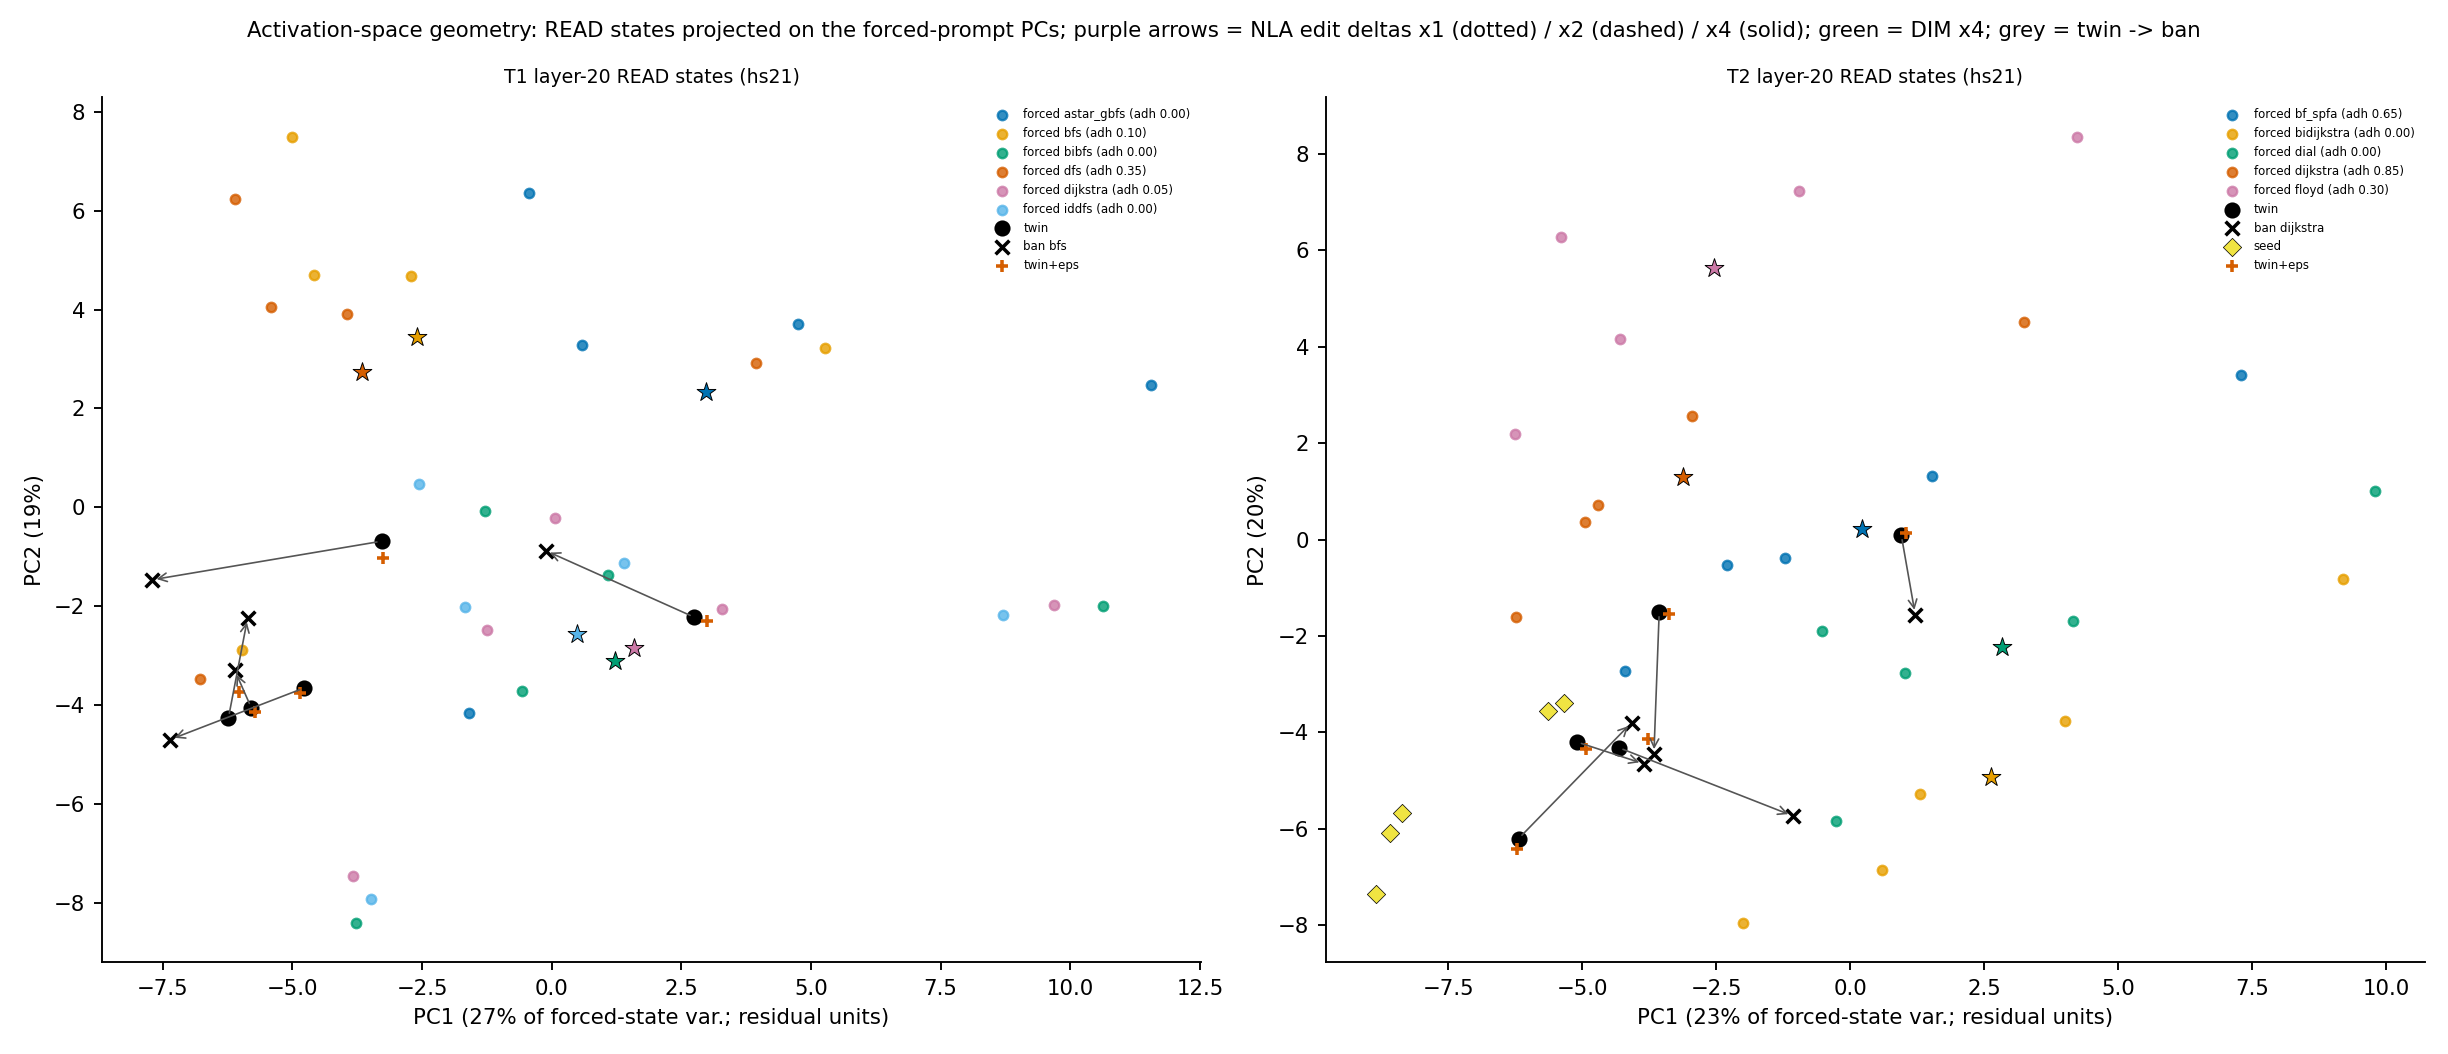

F8_mds_centroids


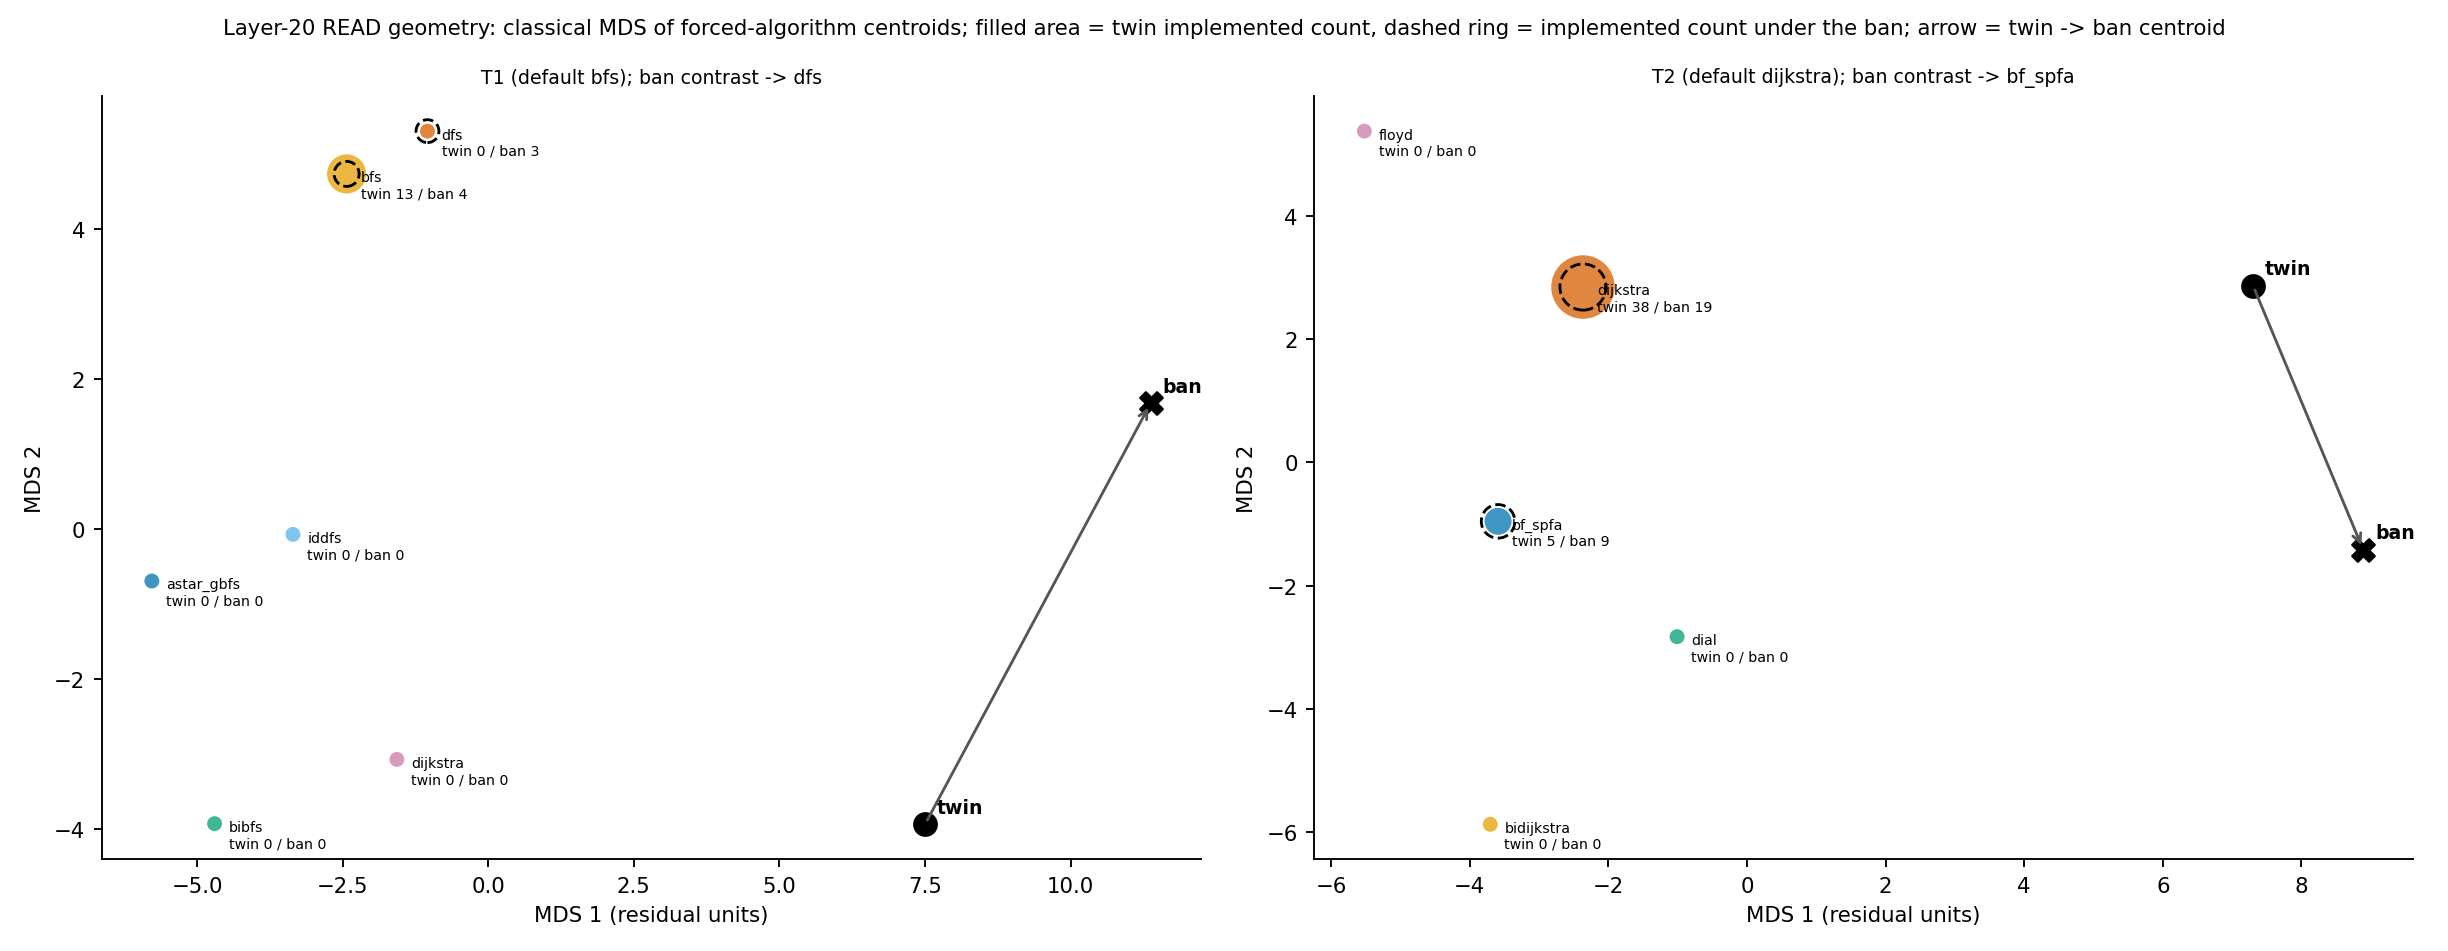

F0_behaviour


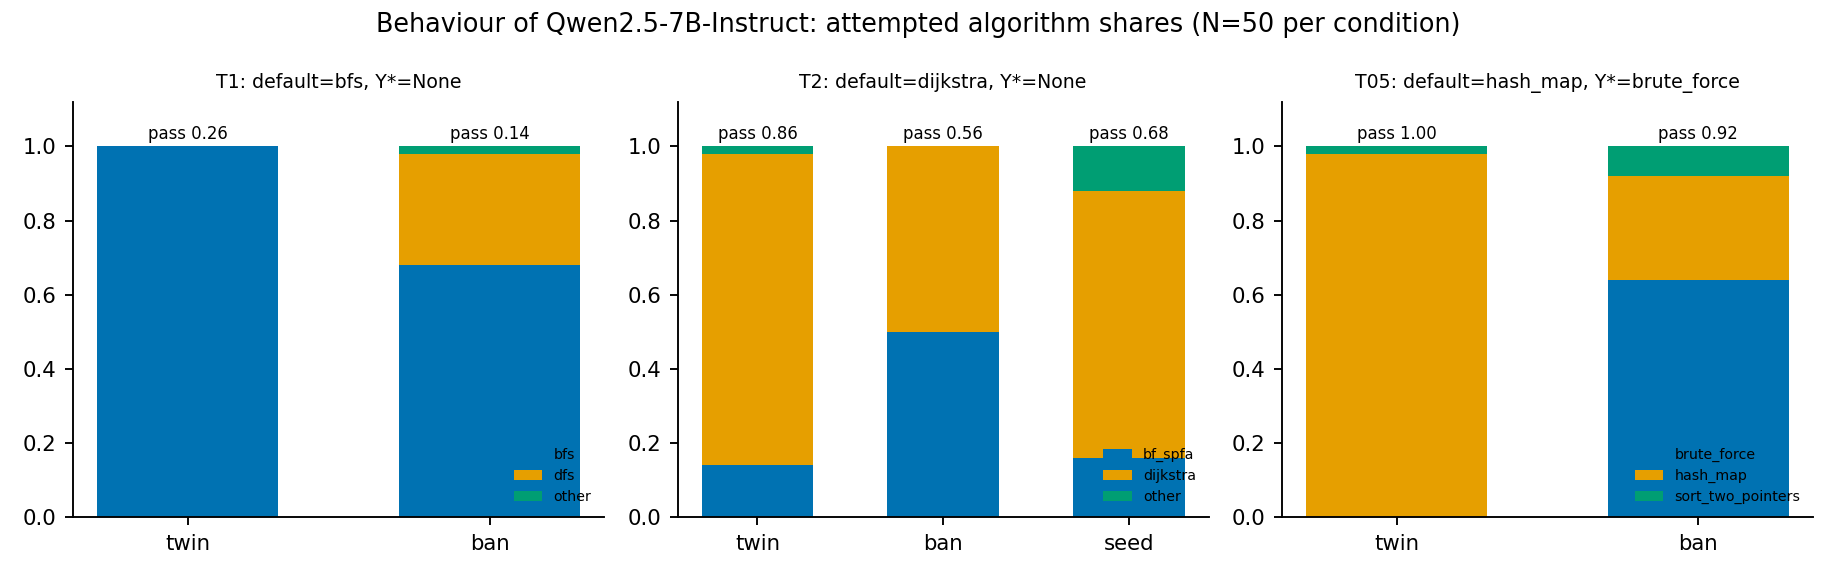

F2_naming


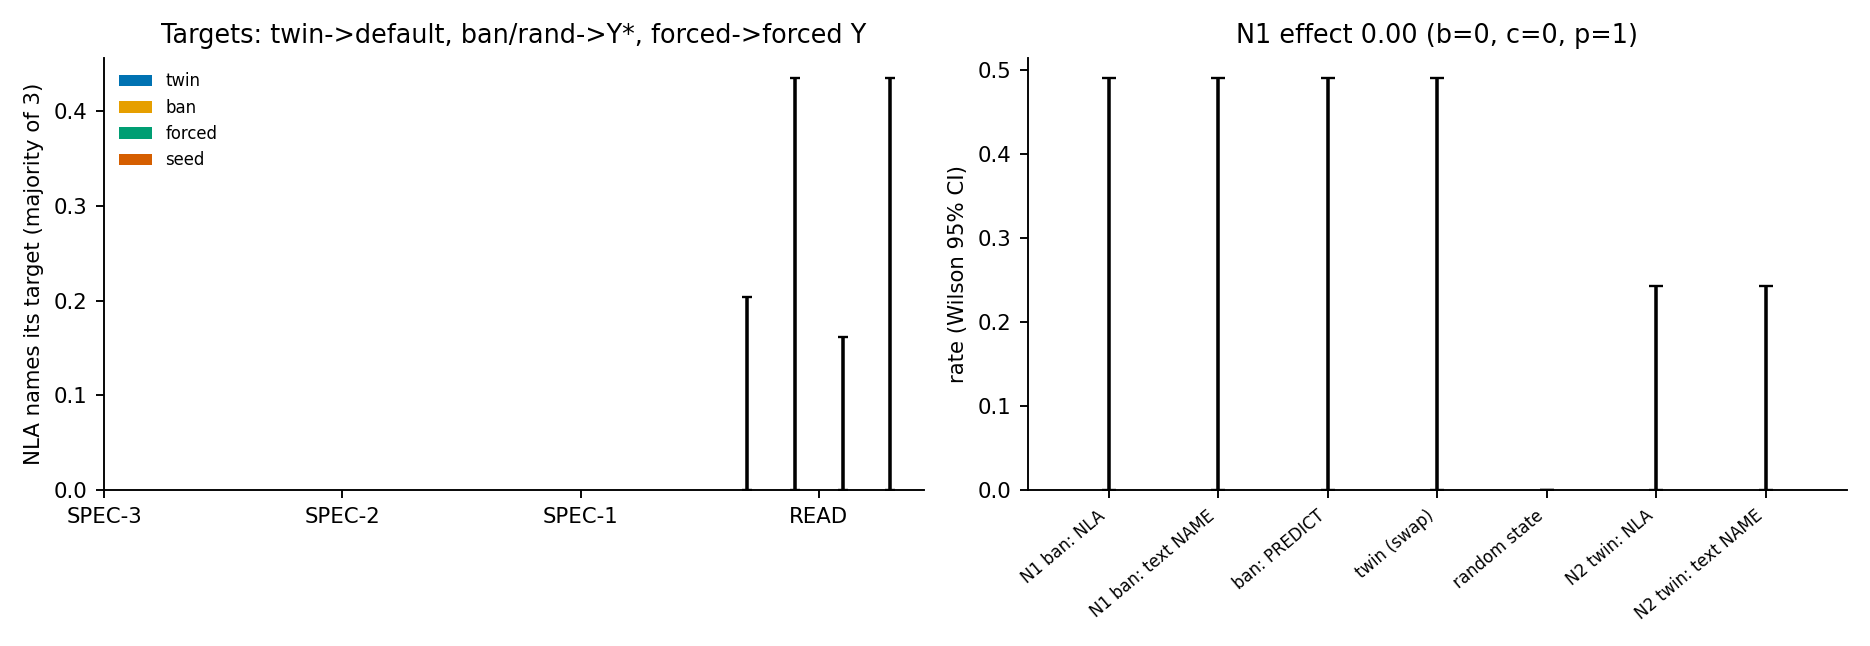

F3_planned_distribution


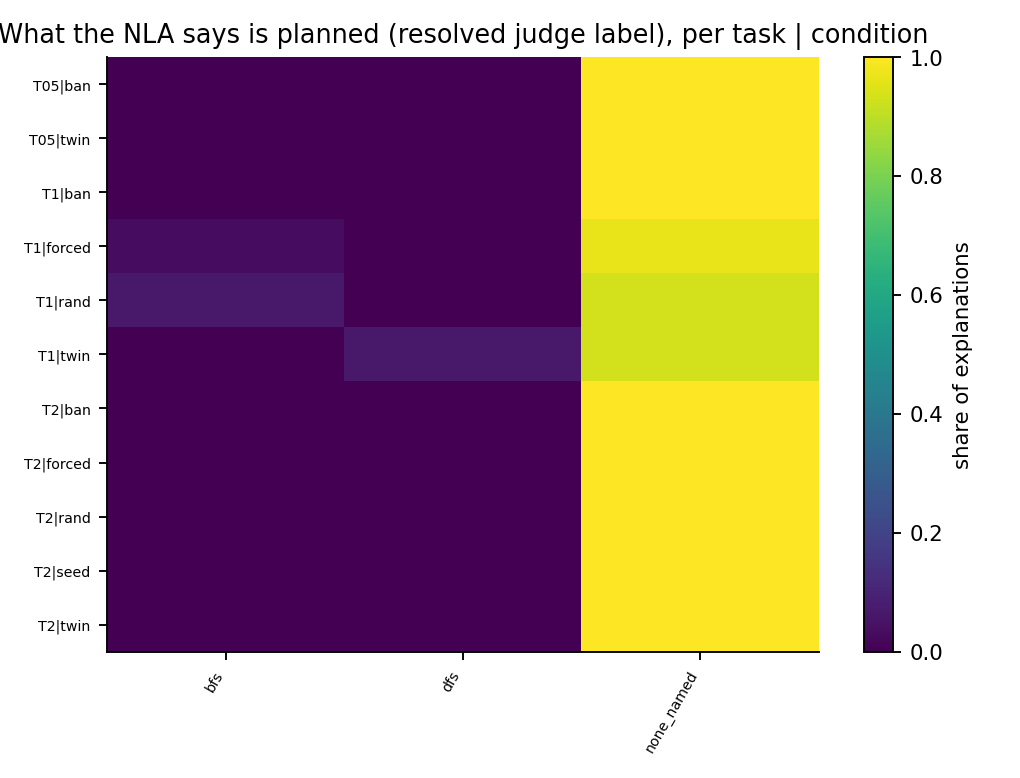

F1_gate


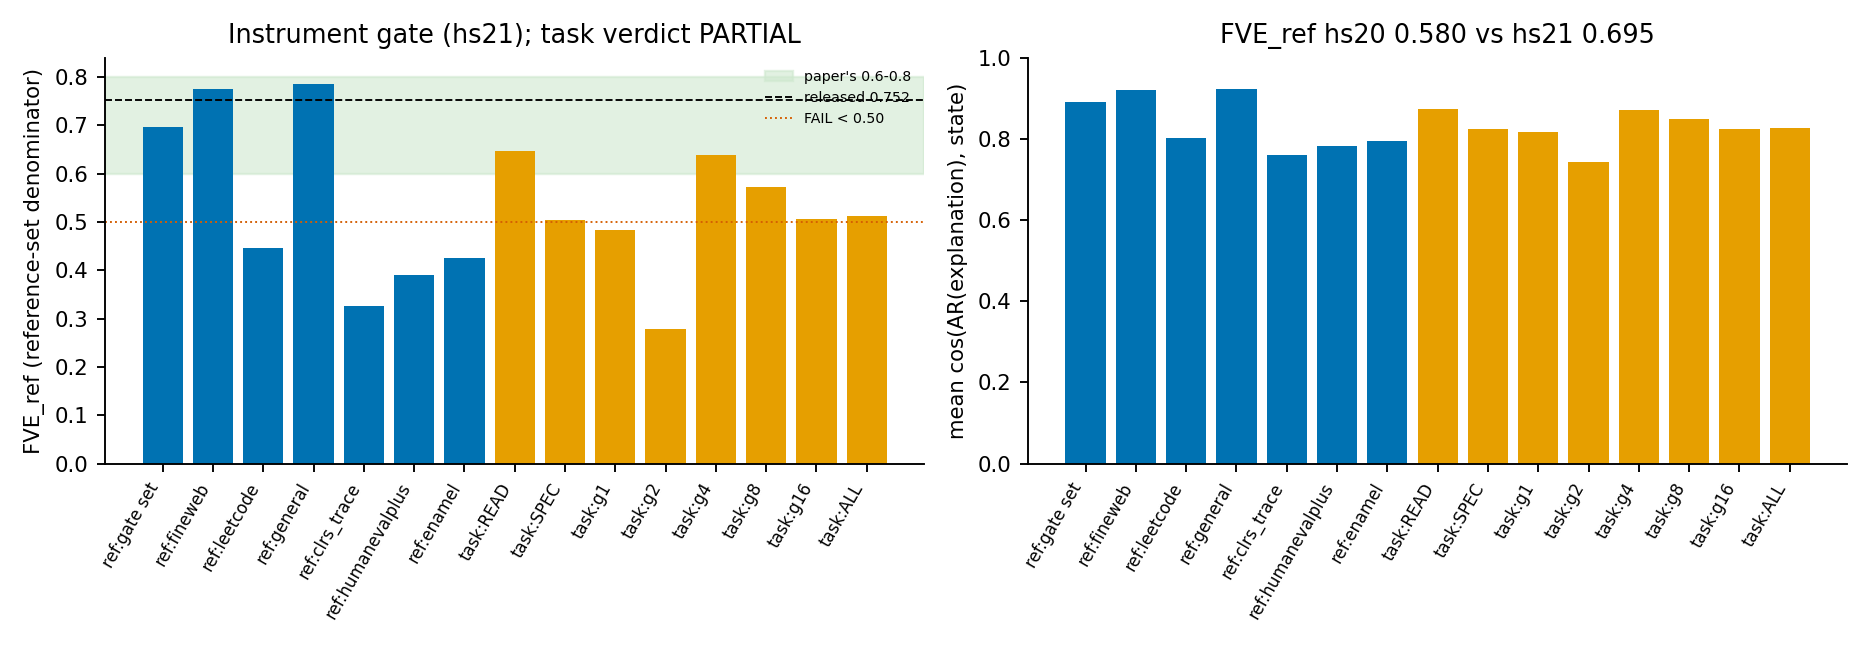

F7_judges


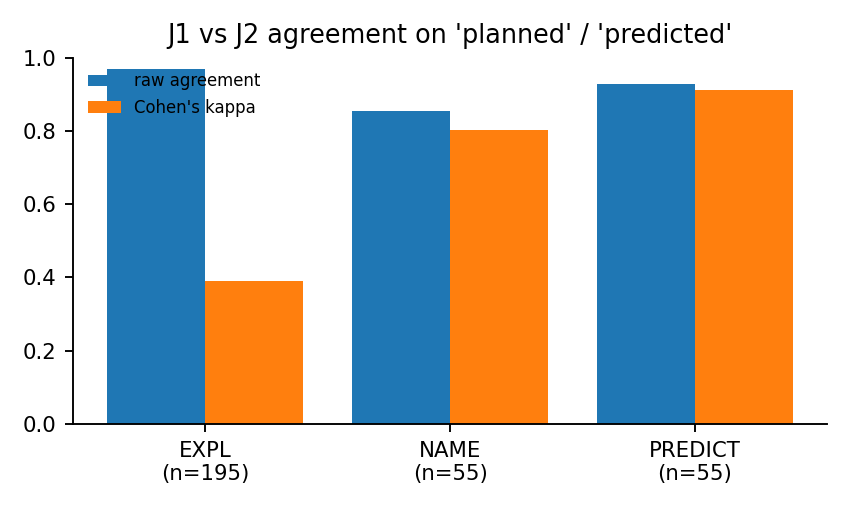

In [21]:
for name in ("F6_geometry", "F8_mds_centroids", "F0_behaviour", "F2_naming", "F3_planned_distribution", "F1_gate", "F7_judges"):
    p = FIG_DIR / f"{name}.png"
    if p.exists():
        print(name)
        display(Image(filename=str(p), width=1150 if name in ("F6_geometry", "F8_mds_centroids", "F0_behaviour") else 850))

### Summary figure

- **(a) Can the plan be read before the code?** Take each judged READ state and the algorithm the model then wrote from that prompt: the modal correct program over its CRN slots. The panel shows how often each reader names that algorithm: the NLA (majority of 3 explanations), the text-only reader (the visible prompt), and the outside reader's forecast.
- **(b) Does the twin state sit nearest the algorithm the model writes?** For each task and mode, the distance from the twin centroid (filled) and the ban centroid (open) to the forced centroid c_m, against the share of correct programs that implement m.
- **(c) Where does the ban push the state?** The cosine of the ban displacement with each mode-specific direction. Bars outlined in black mark the banned default.

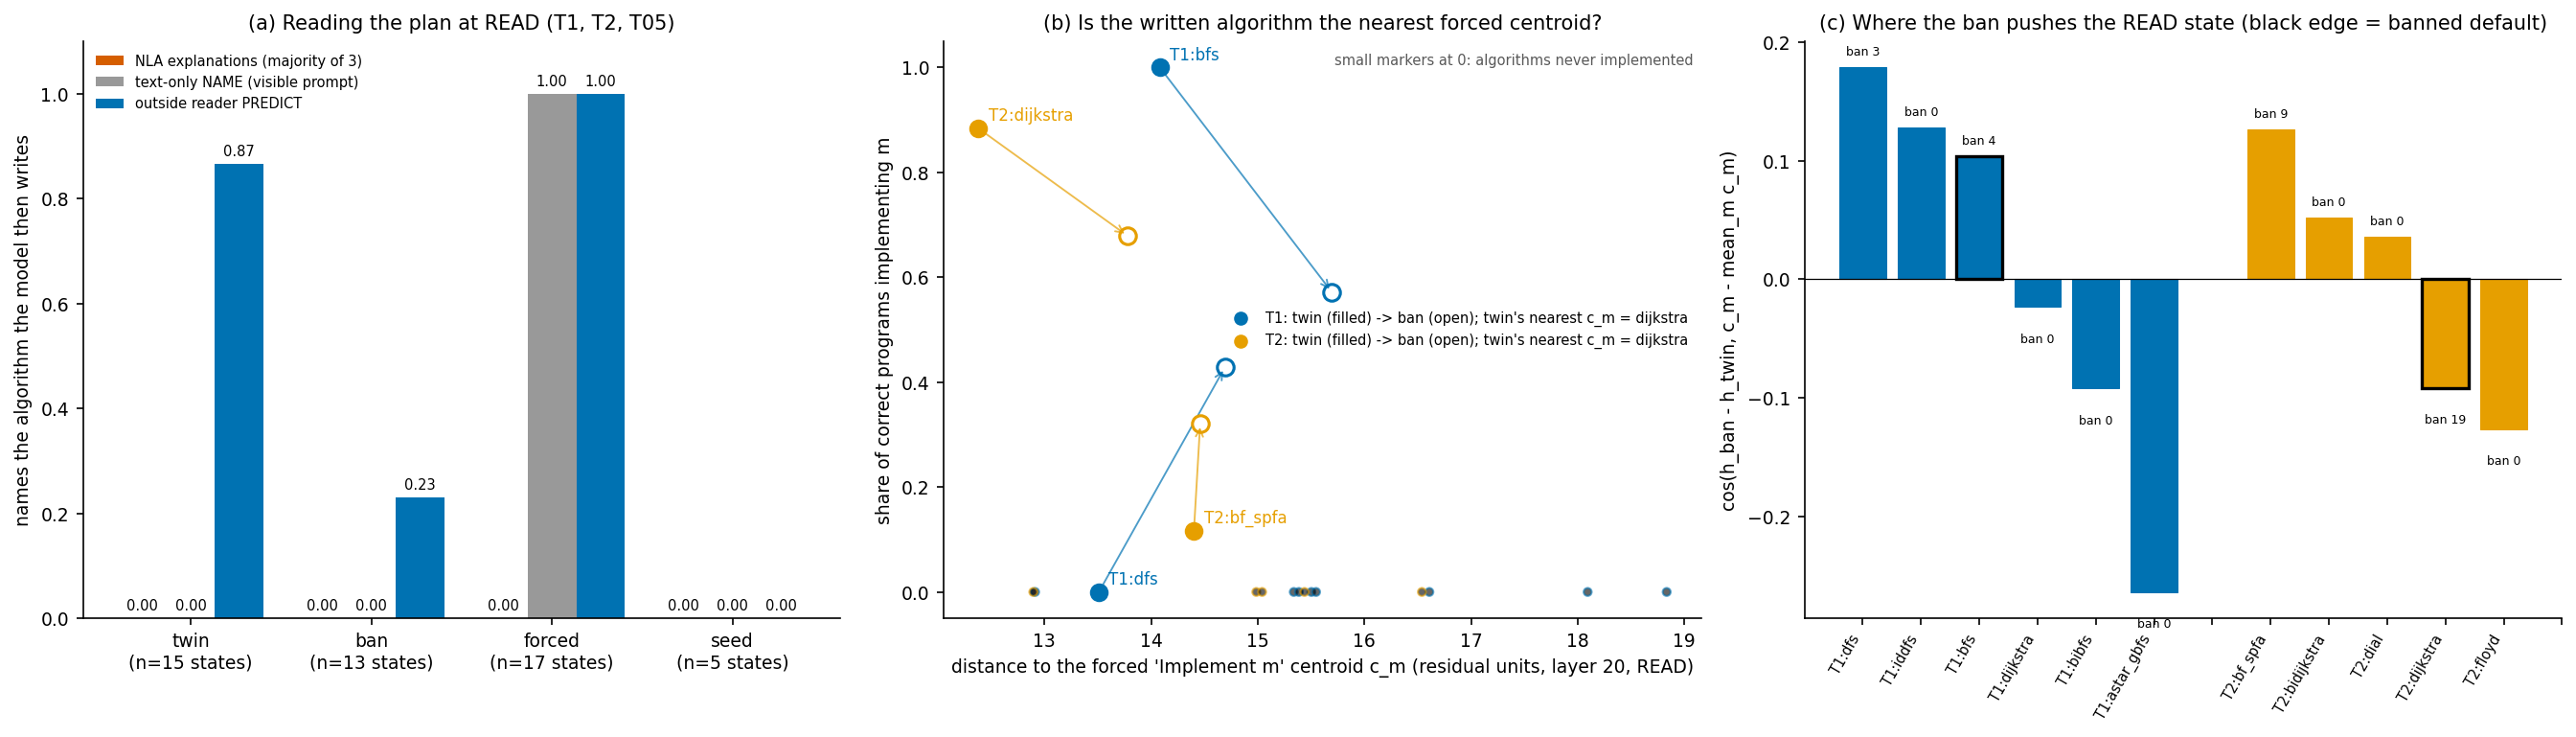

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# (a) readers vs the realised algorithm, judged READ states
ax = axes[0]
groups = ["twin", "ban", "forced", "seed"]
readers = [("predict_nla", "NLA explanations (majority of 3)", PAL[3]),
           ("predict_text_only_name", "text-only NAME (visible prompt)", PAL[7]),
           ("predict_outside_reader", "outside reader PREDICT", PAL[0])]
units = {g: [e for e in EX if e["metadata_condition"] == g and e["metadata_in_readout_set"]
             and e["output"] != "no_correct_program"] for g in groups}
for i, (field, lab, col) in enumerate(readers):
    vals = [np.mean([e[field] == e["output"] for e in units[g]]) for g in groups]
    ax.bar(np.arange(len(groups)) + (i - 1) * 0.27, vals, width=0.27, color=col, label=lab)
    for j, v in enumerate(vals):
        ax.text(j + (i - 1) * 0.27, v + 0.015, f"{v:.2f}", ha="center", fontsize=7)
ax.set_xticks(range(len(groups)), [f"{g}\n(n={len(units[g])} states)" for g in groups])
ax.set_ylim(0, 1.1)
ax.set_ylabel("names the algorithm the model then writes")
ax.set_title("(a) Reading the plan at READ (T1, T2, T05)", fontsize=10)
ax.legend(frameon=False, fontsize=7, loc="upper left")

# (b) distance to each forced centroid vs implemented share, twin (filled) and ban (open)
ax = axes[1]
for t, col in zip(GEOMETRY_TASKS, (PAL[0], PAL[1])):
    G = geo["tasks"][t]
    it, ib = G["implemented_twin"], G["implemented_ban"]
    nt, nb = sum(it.values()), sum(ib.values())
    for m, dt in G["READ"]["dist_twin_to_forced"].items():
        db = G["READ"]["dist_ban_to_forced"][m]
        st, sb = it.get(m, 0) / nt, ib.get(m, 0) / nb
        if st == 0 and sb == 0:  # never implemented under twin or ban: small unlabelled markers on the axis
            ax.scatter([dt, db], [0, 0], s=16, color=["none", "none"], edgecolor=col, alpha=0.6, zorder=2)
            continue
        ax.scatter(dt, st, s=70, color=col, zorder=3)
        ax.scatter(db, sb, s=70, facecolor="white", edgecolor=col, lw=1.5, zorder=3)
        ax.annotate("", xy=(db, sb), xytext=(dt, st), arrowprops=dict(arrowstyle="->", color=col, lw=0.9, alpha=0.7))
        ax.annotate(f"{t}:{m}", (dt, st), textcoords="offset points", xytext=(5, 4), fontsize=8, color=col)
    near = min(G["READ"]["dist_twin_to_forced"], key=G["READ"]["dist_twin_to_forced"].get)
    ax.scatter([], [], color=col, label=f"{t}: twin (filled) -> ban (open); twin's nearest c_m = {near}")
ax.set_xlabel("distance to the forced 'Implement m' centroid c_m (residual units, layer 20, READ)")
ax.set_ylabel("share of correct programs implementing m")
ax.set_title("(b) Is the written algorithm the nearest forced centroid?", fontsize=10)
ax.text(0.99, 0.98, "small markers at 0: algorithms never implemented", transform=ax.transAxes, ha="right",
        va="top", fontsize=7, color="0.35")
ax.legend(frameon=False, fontsize=7)

# (c) ban displacement vs the mode-specific directions
ax = axes[2]
xs, labels_c = 0, []
for t, col in zip(GEOMETRY_TASKS, (PAL[0], PAL[1])):
    G = geo["tasks"][t]
    cc = G["READ"]["ban_contrast_cos"]
    for m in sorted(cc, key=cc.get, reverse=True):
        ax.bar(xs, cc[m], color=col, edgecolor="k" if m == G["default"] else col, lw=1.6 if m == G["default"] else 0.5)
        ax.text(xs, cc[m] + (0.01 if cc[m] >= 0 else -0.03), f"ban {G['implemented_ban'].get(m, 0)}", ha="center", fontsize=6)
        labels_c.append(f"{t}:{m}")
        xs += 1
    xs += 1
    labels_c.append("")
ax.axhline(0, color="k", lw=0.6)
ax.set_xticks(range(len(labels_c)), labels_c, rotation=60, ha="right", fontsize=7)
ax.set_ylabel("cos(h_ban - h_twin, c_m - mean_m c_m)")
ax.set_title("(c) Where the ban pushes the READ state (black edge = banned default)", fontsize=10)
fig.tight_layout()
plt.show()

## Takeaways

These are the results on the demo states: the 100 layer-20 READ states of T1, T2 and T05, replayed with the artifact's own code.

**1. The model writes the "average" algorithm, and a ban rarely replaces it.**
- **T1 grid path:** BFS in 13 of 13 correct twin programs. Under "do not use BFS", 68% of attempts are still BFS; 15 of the 50 CRN pairs flip from BFS to DFS. The correct ban programs are BFS 4 and DFS 3.
- **T2 weighted shortest path:** Dijkstra 38 against Bellman-Ford/SPFA 5. Under the ban, half the attempts use Bellman-Ford/SPFA (19 CRN pairs flip from Dijkstra), but only 9 Bellman-Ford programs pass the hidden tests, against 19 for Dijkstra. That is below the frozen substitute rule (≥ 10 correct programs and ≥ 50% of the correct ones), so T2 has no substitute.
- **T05 two-sum** is the exception: banning the hash map gives a brute-force double loop in 32 of 46 correct programs (Y\*).
- **The T2 semantic seed**, a story that describes Bellman-Ford-like rounds, barely moves the choice: Dijkstra 28, Bellman-Ford 6.
- **Asking directly works for the attempt, not always the pass.** "Implement Y" makes all 20 attempts use the requested algorithm for T1's BFS and DFS and for T2's Dijkstra and Floyd-Warshall (Bellman-Ford: 19 of 20). On T1, adherence counts only correct programs, and most programs fail the grid task's hidden tests, so adherence stays low (BFS 0.10, DFS 0.35).

These numbers equal the full run's `results/behaviour.json`, field for field.

**2. The NLA does not put the plan into words at the end of the prompt.**
- Every committed test gives the NLA 0:
  - N1: 0 of 4 T05 ban states name brute force.
  - N2: 0 of 12 twin states name the default.
  - N8b: 0 of 8 ban-failure states name the default the model still writes.
  - N3, the positive control: 0 of 20 forced "Implement Y" states name Y, against 20 of 20 for the text-only reader.
- The explanations describe the prompt's format line and invent a different task: for "Implement BFS" they talk about longest increasing subsequences, prime checking and N-Queens.
- An outside reader that sees only the prompt predicts the written algorithm much better: 0.87 on twin prompts (summary panel a).
- The full run gives the same verdict at all four prefill positions and on seven tasks (N1 0/16, N2 0/112, N8b 0/96).
- This is not because the NLA is blind. The full run's exploratory local control read the state *at the algorithm-name token* and found the name mentioned 80–89% of the time; the identity fades within one sentence of the prompt.

**3. In activation space the choice has a geometry, but behaviour follows it only partly.**
- Each forced "Implement m" prompt occupies its own region at layer 20 (F6, F8).
- On both tasks, the neutral twin state is nearest to the forced *Dijkstra* centroid, although on T1 the model writes BFS (summary panel b).
- The ban moves the READ state toward an alternative's mode-specific direction: DFS on T1 (cos +0.18), Bellman-Ford on T2 (+0.13, with Dijkstra at −0.09). The attempts move the same way, to DFS on T1 (30%) and to Bellman-Ford on T2 (50%), but the default keeps 68% of the attempts on T1 and 50% on T2 (panel c, F0).

These values equal the full run's `results/geometry.json`.

**4. The bookkeeping reproduces.**
- All 305 stored judge verdicts re-resolve from the raw J1/J2/J3 answers with 0 differences.
- The standard-library audit reproduces every readout test, and its placebo shows no effect.
- On the demo's explanations, the AR fidelity is FVE_ref 0.650, matching the full run's READ class (0.646).

**Caveats.**
- There is one model, one layer and one released AV checkpoint.
- Code is out of distribution for this NLA: FVE_ref is 0.51 on the task states, a PARTIAL gate.
- The demo has READ states only.
- The geometry is exploratory and rests on 5 templates per condition.

**Context from the full run (not replayed here).**
- Exploratory steering at READ plus the first 64 generated tokens, with the NLA edit ×8, moved T06 to Floyd 0.76, against 0.28 without it. It beat matched random, unrelated-word and round-trip pushes.
- Prompting stays the ceiling: "Implement Y" adherence is 0.90–1.00 on the causal tasks.
- No program in any arm was a genuinely new algorithm.